# Missing values and outliers in A/B tests: reproducible report

This notebook collects every artifact of the paper in one place: library versions, the data
checksum, unit tests, experiments 0-4, tables and figures. Run it top to bottom
(`Kernel -> Restart & Run All`) and commit it with outputs.

Parameters are environment variables set in the first cell: `QUICK=1` for a smoke run,
`N_SIM` for Monte Carlo replications. With `RUN_EXPERIMENTS = False` the notebook only displays
results already stored in `results/`.

In [1]:
import os, sys, subprocess, json, pathlib
os.environ.setdefault("QUICK", "0")          # "1" for a quick smoke run
os.environ.setdefault("SOURCE", "hillstrom")
ROOT = pathlib.Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
RUN_EXPERIMENTS = os.environ.get("RUN_EXPERIMENTS", "1") == "1"   # False: only show results/*.csv

In [2]:
import platform, numpy, pandas, scipy, matplotlib
print("python", platform.python_version(), "| numpy", numpy.__version__, "| pandas", pandas.__version__,
      "| scipy", scipy.__version__, "| matplotlib", matplotlib.__version__)
from abtest_sim import config
print("QUICK =", config.QUICK, "| N_SIM =", config.N_SIM, "| WORKERS =", config.WORKERS, "| SEED =", config.SEED)

python 3.14.4 | numpy 2.5.4 | pandas 3.1.1 | scipy 1.18.1 | matplotlib 3.11.2
QUICK = False | N_SIM = 1000 | WORKERS = 6 | SEED = 20261111


## 1. Data

The file is downloaded once into `data/hillstrom.csv`. The checksum records which version of the file produced the results.

In [3]:
from abtest_sim.data import download_hillstrom, sha256, HILLSTROM_FILE
download_hillstrom()
print(HILLSTROM_FILE.name, sha256(HILLSTROM_FILE))

hillstrom.csv 0e5893329d8b93cefecc571777672028290ab69865718020c78c7284f291aece


## 2. Code checks

Unit tests check the implementation (Welch matches `scipy`, missing rates are calibrated, post-stratification has nominal coverage without missing data). They test the tool, not the results.

In [4]:
r = subprocess.run([sys.executable, "-m", "pytest", "-q", "tests/"], capture_output=True, text=True)
print(r.stdout[-2000:], r.stderr[-2000:])

........                                                                 [100%]
8 passed in 1.82s
 


## 3. Running the experiments

Each script writes a CSV and a `*.meta.json` (run time, versions, replications) into `results/`.

In [5]:
def run(mod):
    print(">>>", mod, flush=True)
    r = subprocess.run([sys.executable, "-m", mod], capture_output=True, text=True, env=os.environ)
    print("\n".join(l for l in r.stdout.replace("\r", "\n").splitlines() if "cells:" not in l)[-3000:])
    if r.returncode:
        print(r.stderr[-3000:]); raise RuntimeError(mod)

mods = ["experiments.exp_0_eda", "experiments.exp_1_missing", "experiments.exp_2_outliers",
        "experiments.exp_3_sample_size", "experiments.exp_4_case_study"]
if RUN_EXPERIMENTS:
    for m in mods:
        run(m)
run("experiments.make_figures"); run("experiments.make_tables")

>>> experiments.make_figures


figures: fig1_distributions.png, fig2_type1_missing.png, fig3_bias_missing.png, fig4_outliers_power.png, fig5_sample_size.png, fig6_case_forest.png, fig7_flip_heatmap_history.png, fig7_flip_heatmap_spend.png, fig7_flip_heatmap_visit.png
>>> experiments.make_tables


written: results/tables.md (44 lines)


## 4. Data description (Table 1, Figure 1)

,group,n
0,Mens E-Mail,21307
1,No E-Mail,21306
2,Womens E-Mail,21387


,metric,n,mean,sd,cv,skew,share_zero,q50,q90,q99,q999,max,q99_pos,n_pos
0,history,21306,240.883,252.739,1.049,2.360,0.000,156.655,561.055,1191.895,1865.144,3345.93,1191.895,21306
1,visit,21306,0.106,0.308,2.902,2.557,0.894,0.000,1.000,1.000,1.000,1.00,1.000,2262
2,conversion,21306,0.006,0.075,13.178,13.101,0.994,0.000,0.000,0.000,1.000,1.00,1.000,122
3,spend,21306,0.653,11.588,17.752,26.366,0.994,0.000,0.000,0.000,165.852,499.00,487.643,122


,metric,covariate,spearman,p
0,history,recency,-0.2174,0.0000
1,history,newbie,0.0944,0.0000
2,history,mean|channel=Multichannel,516.5902,NaN
3,history,mean|channel=Phone,200.4702,NaN
4,history,mean|channel=Web,204.4411,NaN
5,visit,recency,-0.0833,0.0000
6,visit,newbie,-0.0891,0.0000
7,visit,mean|channel=Multichannel,0.1285,NaN
8,visit,mean|channel=Phone,0.0872,NaN
9,visit,mean|channel=Web,0.1189,NaN


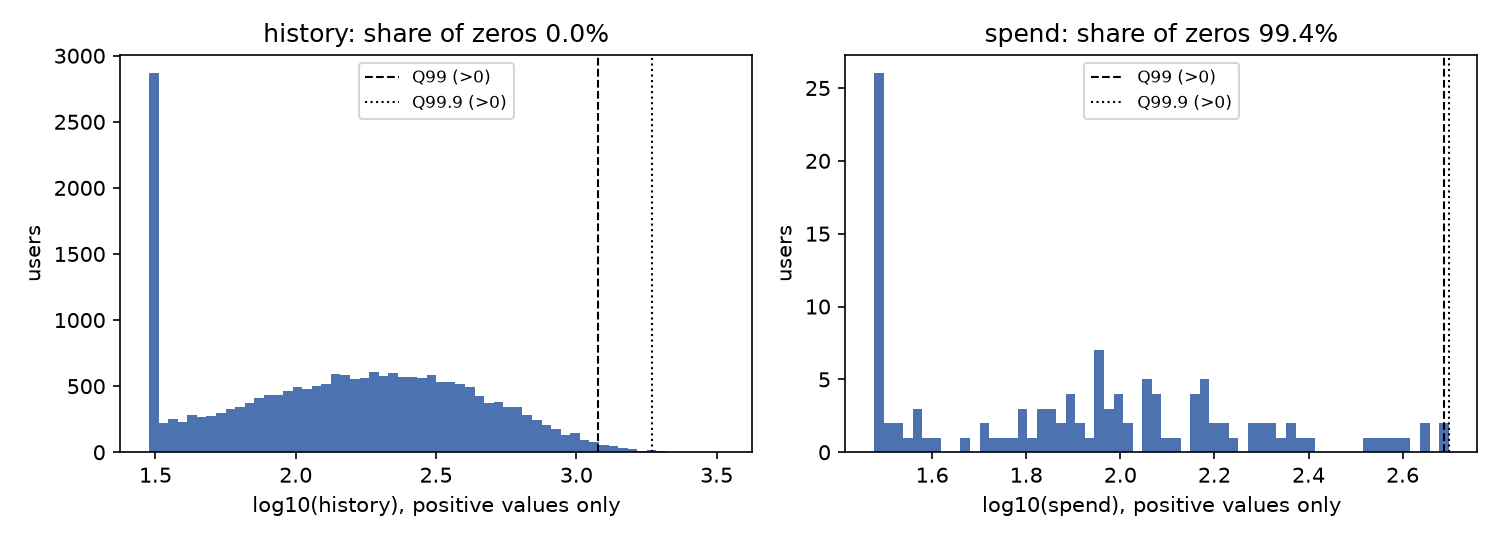

In [6]:
import pandas as pd
from IPython.display import Image, Markdown, display
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)
display(pd.read_csv("results/eda_groups.csv"))
display(pd.read_csv("results/eda_metrics.csv").round(3))
display(pd.read_csv("results/eda_covariates.csv").round(4))
display(Image("figures/fig1_distributions.png"))

## 5. Experiment 1: missing values (Figures 2, 3)

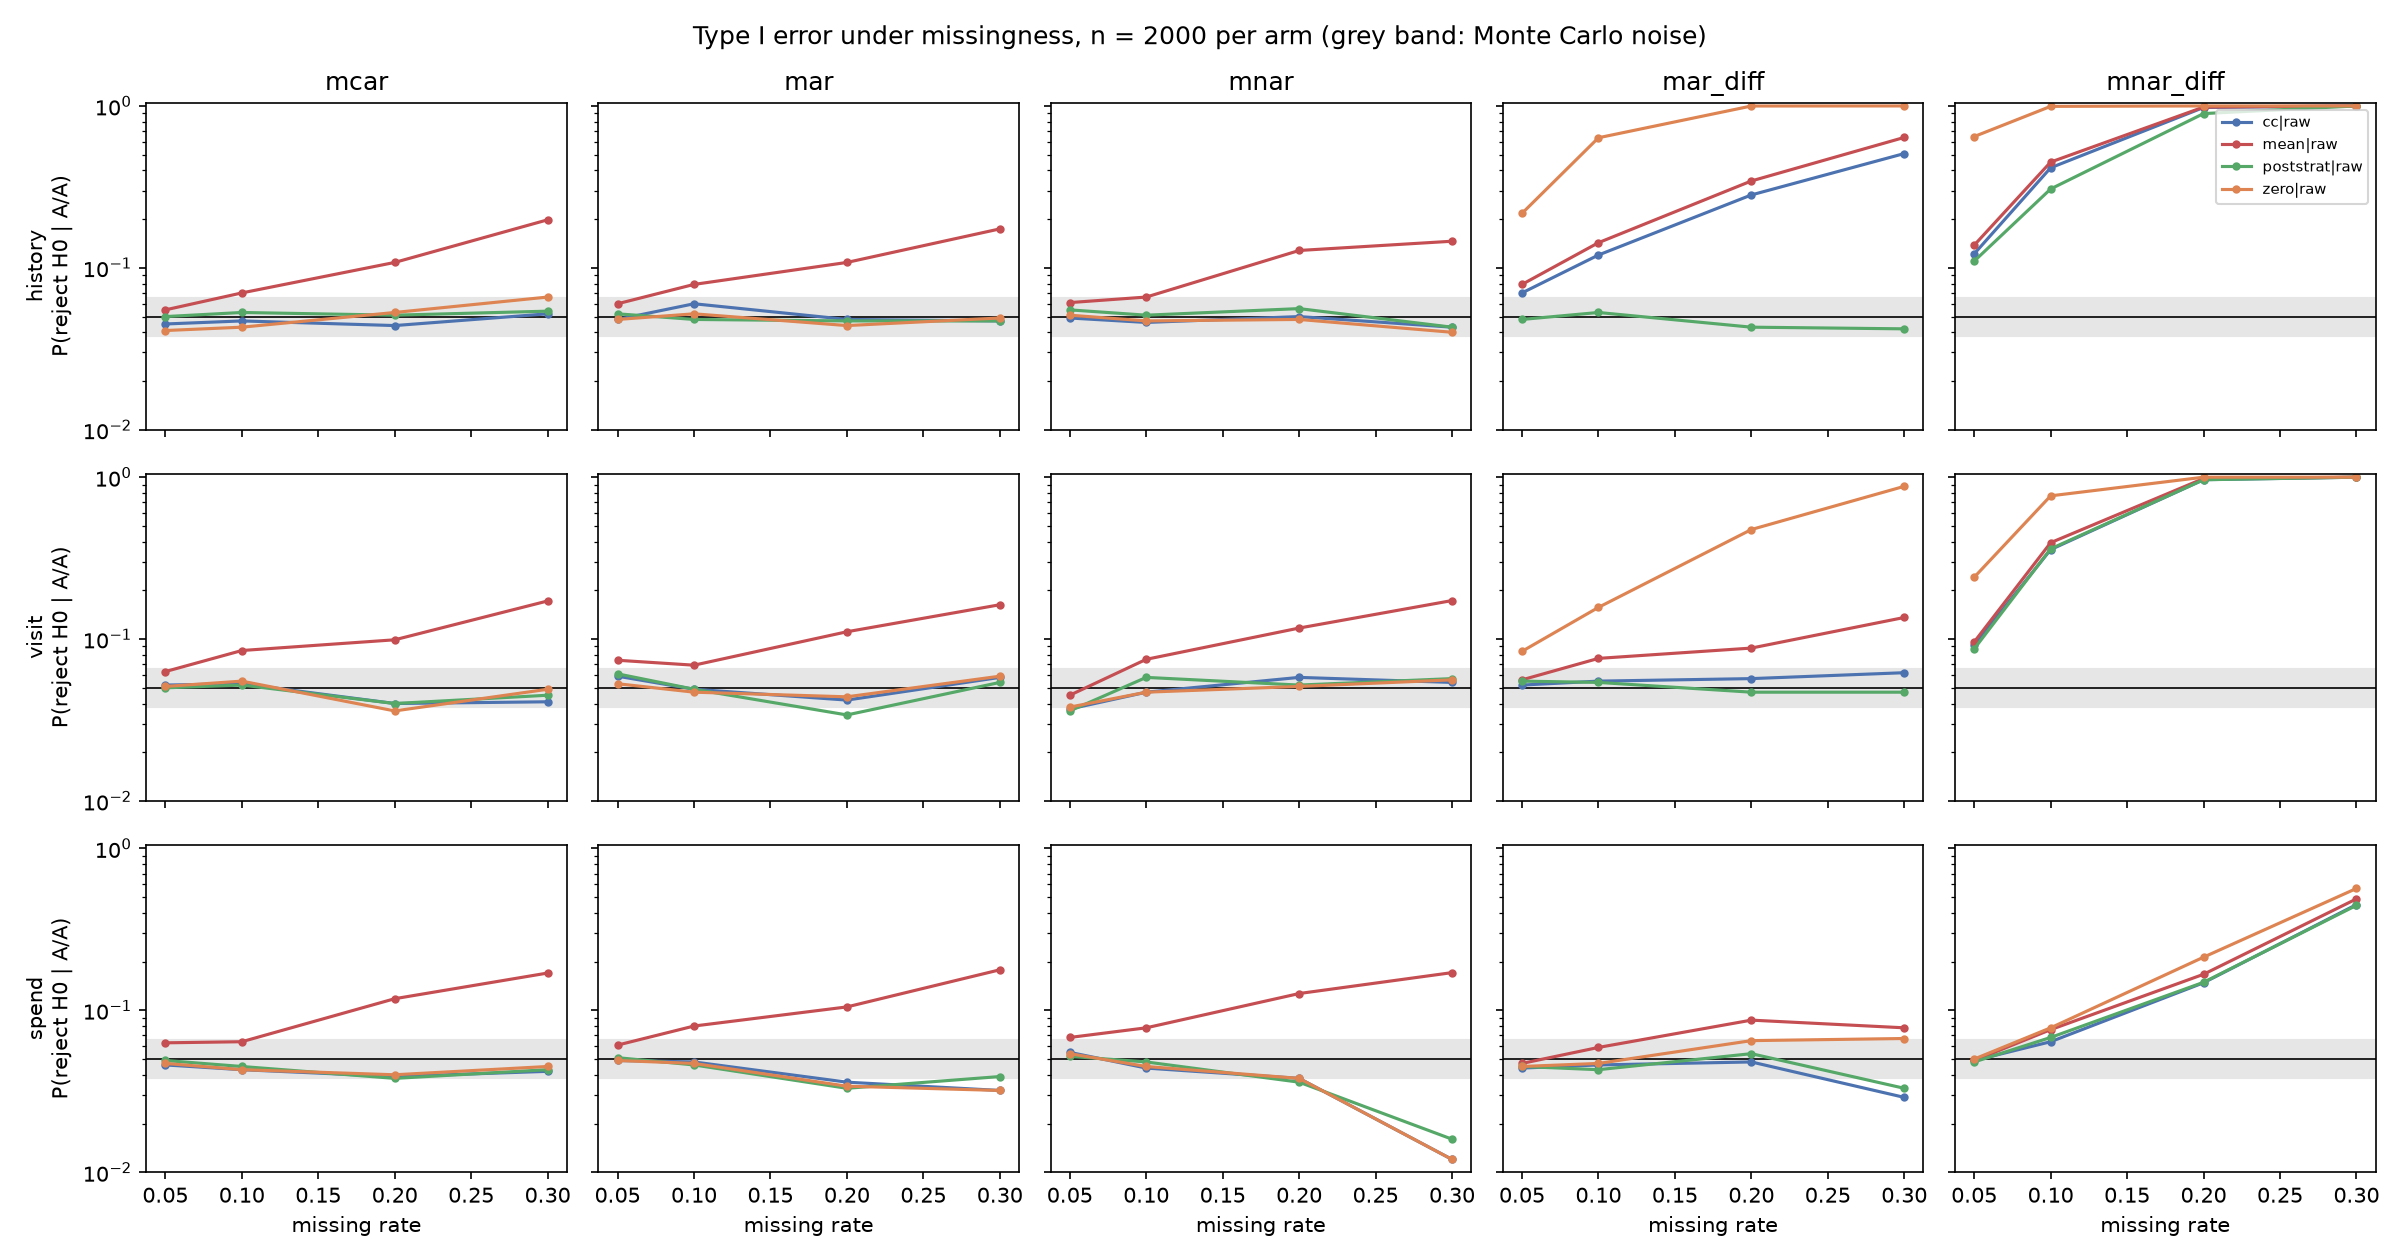

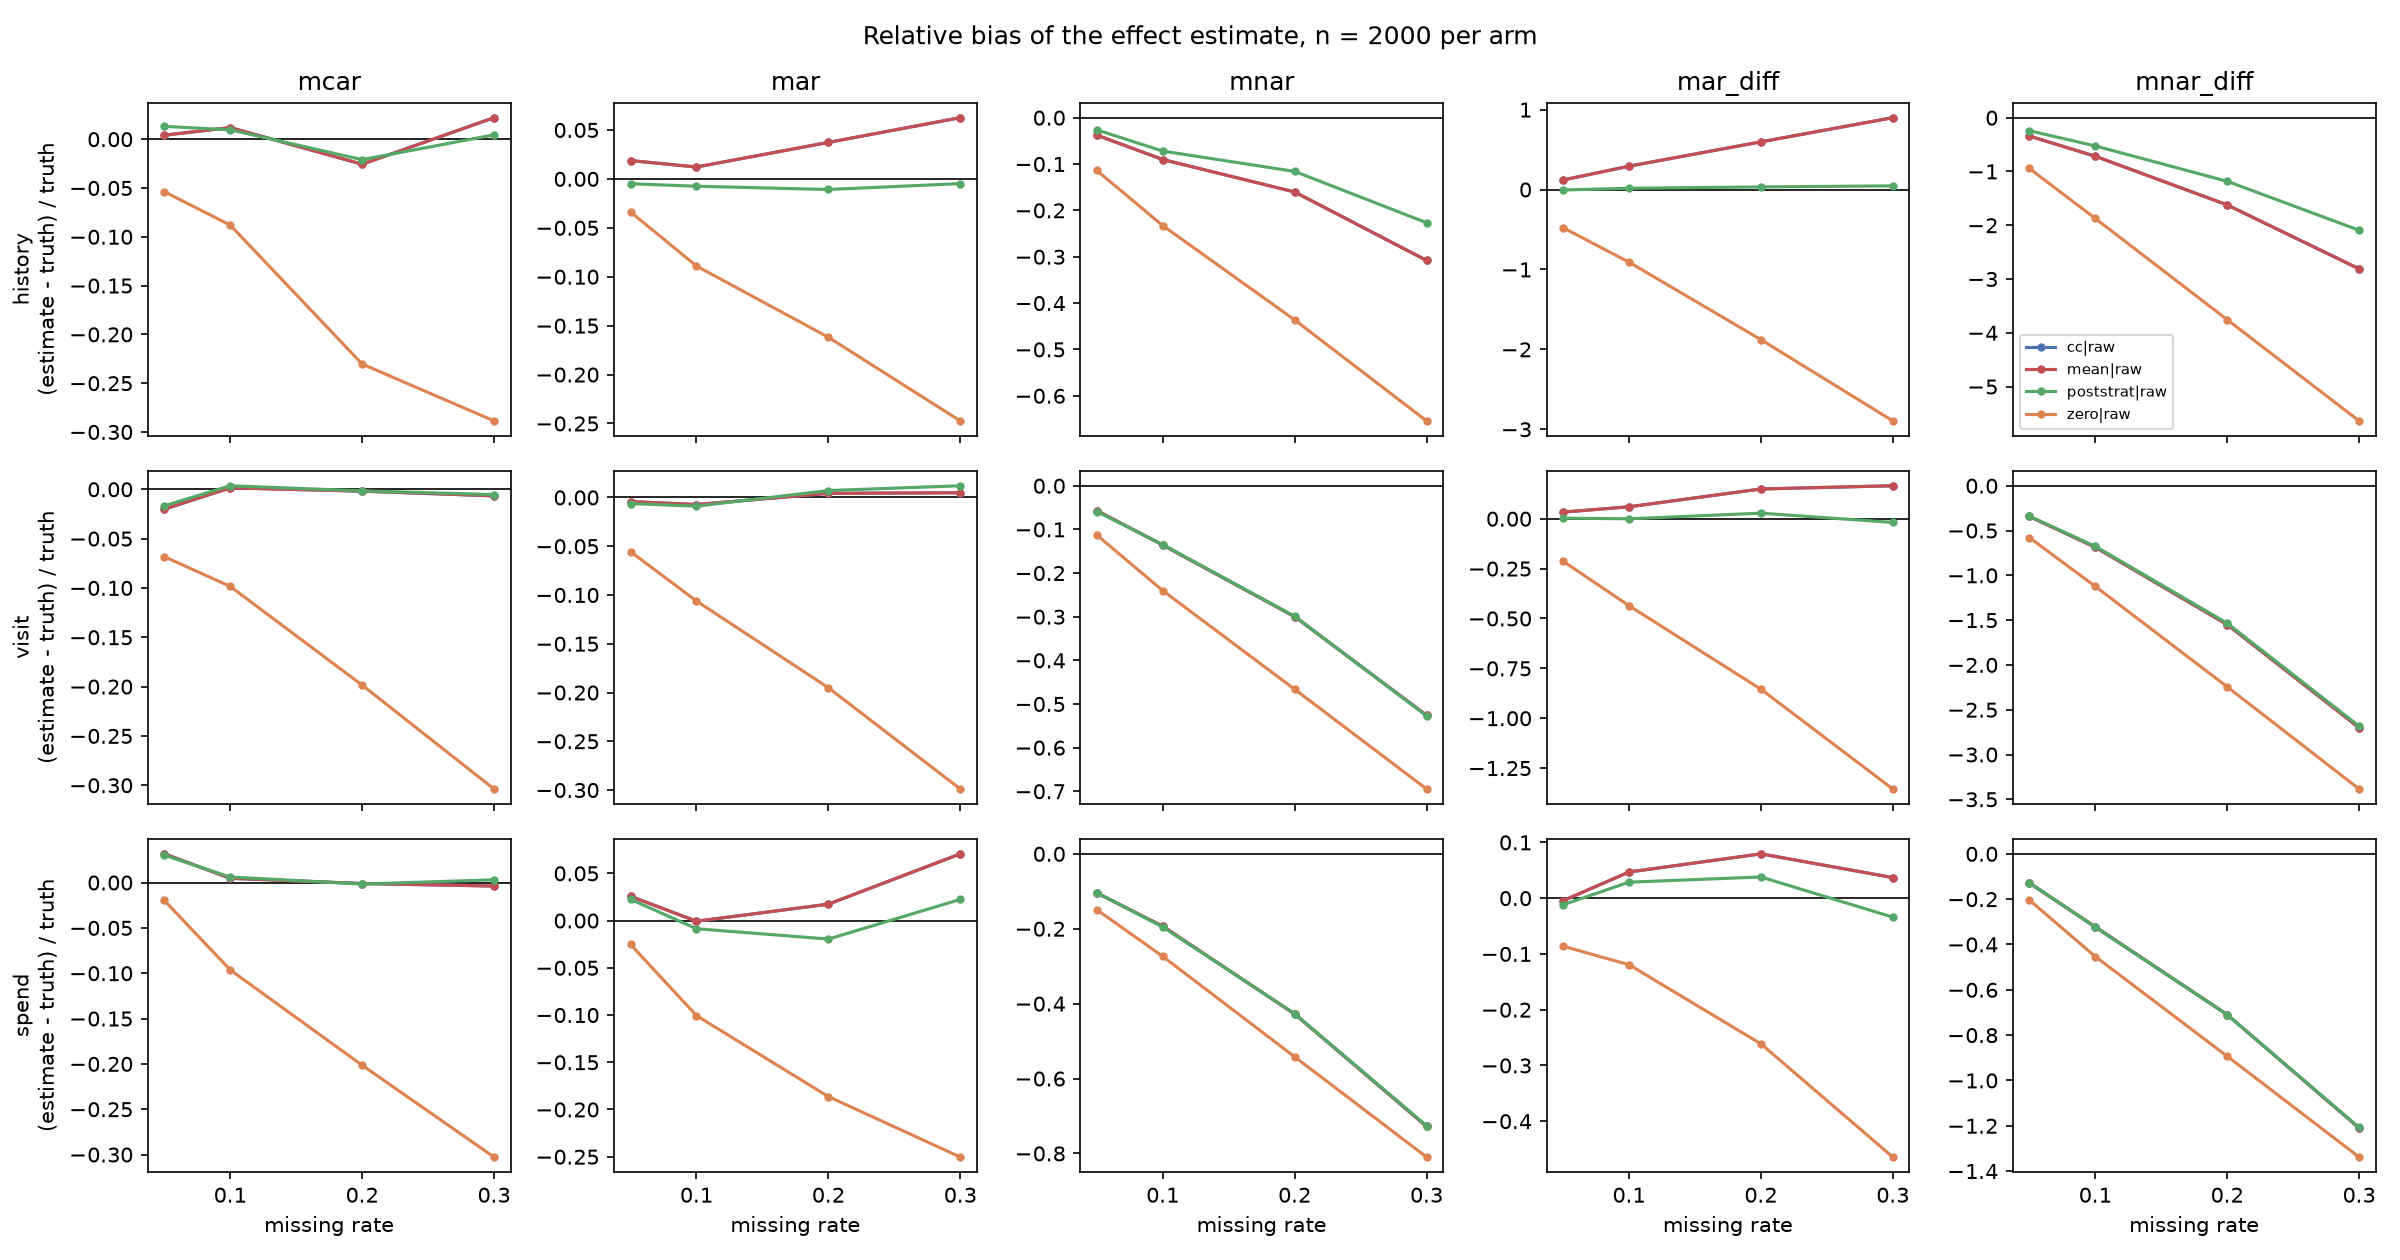

In [7]:
display(Image("figures/fig2_type1_missing.png"))
display(Image("figures/fig3_bias_missing.png"))

Calibration on clean data and the mean-imputation benchmark $2\\bar\\Phi(1.96(1-r))$:

In [8]:
from scipy.stats import norm
e1 = pd.read_csv("results/exp1_missing.csv")
display(e1[e1.handler == "cc|raw"].groupby(["metric", "scenario", "n"]).clean_rej_rate.mean().unstack().round(3))
m = e1[(e1.scenario == "aa") & (e1.mech == "mcar") & (e1.handler == "mean|raw")]
t = m.pivot_table(index=["metric", "n"], columns="rate", values="rej_rate")
t.loc[("formula", 0), :] = [2 * norm.sf(1.959964 * (1 - r)) for r in t.columns]
display(t.round(3))

n                 500    2000   10000
metric  scenario                     
history aa        0.050  0.048  0.049
        effect    0.727  0.761  0.788
spend   aa        0.019  0.044  0.048
        effect    0.031  0.241  0.518
visit   aa        0.051  0.048  0.051
        effect    0.716  0.757  0.780

rate            0.05   0.10   0.20   0.30
metric  n                                
history 500    0.062  0.068  0.119  0.187
        2000   0.055  0.070  0.108  0.198
        10000  0.065  0.077  0.113  0.178
spend   500    0.030  0.060  0.074  0.168
        2000   0.063  0.064  0.118  0.170
        10000  0.066  0.076  0.109  0.196
visit   500    0.078  0.088  0.101  0.182
        2000   0.063  0.085  0.099  0.172
        10000  0.069  0.095  0.112  0.169
formula 0      0.063  0.078  0.117  0.170

## 6. Experiment 2: outliers (Figure 4)

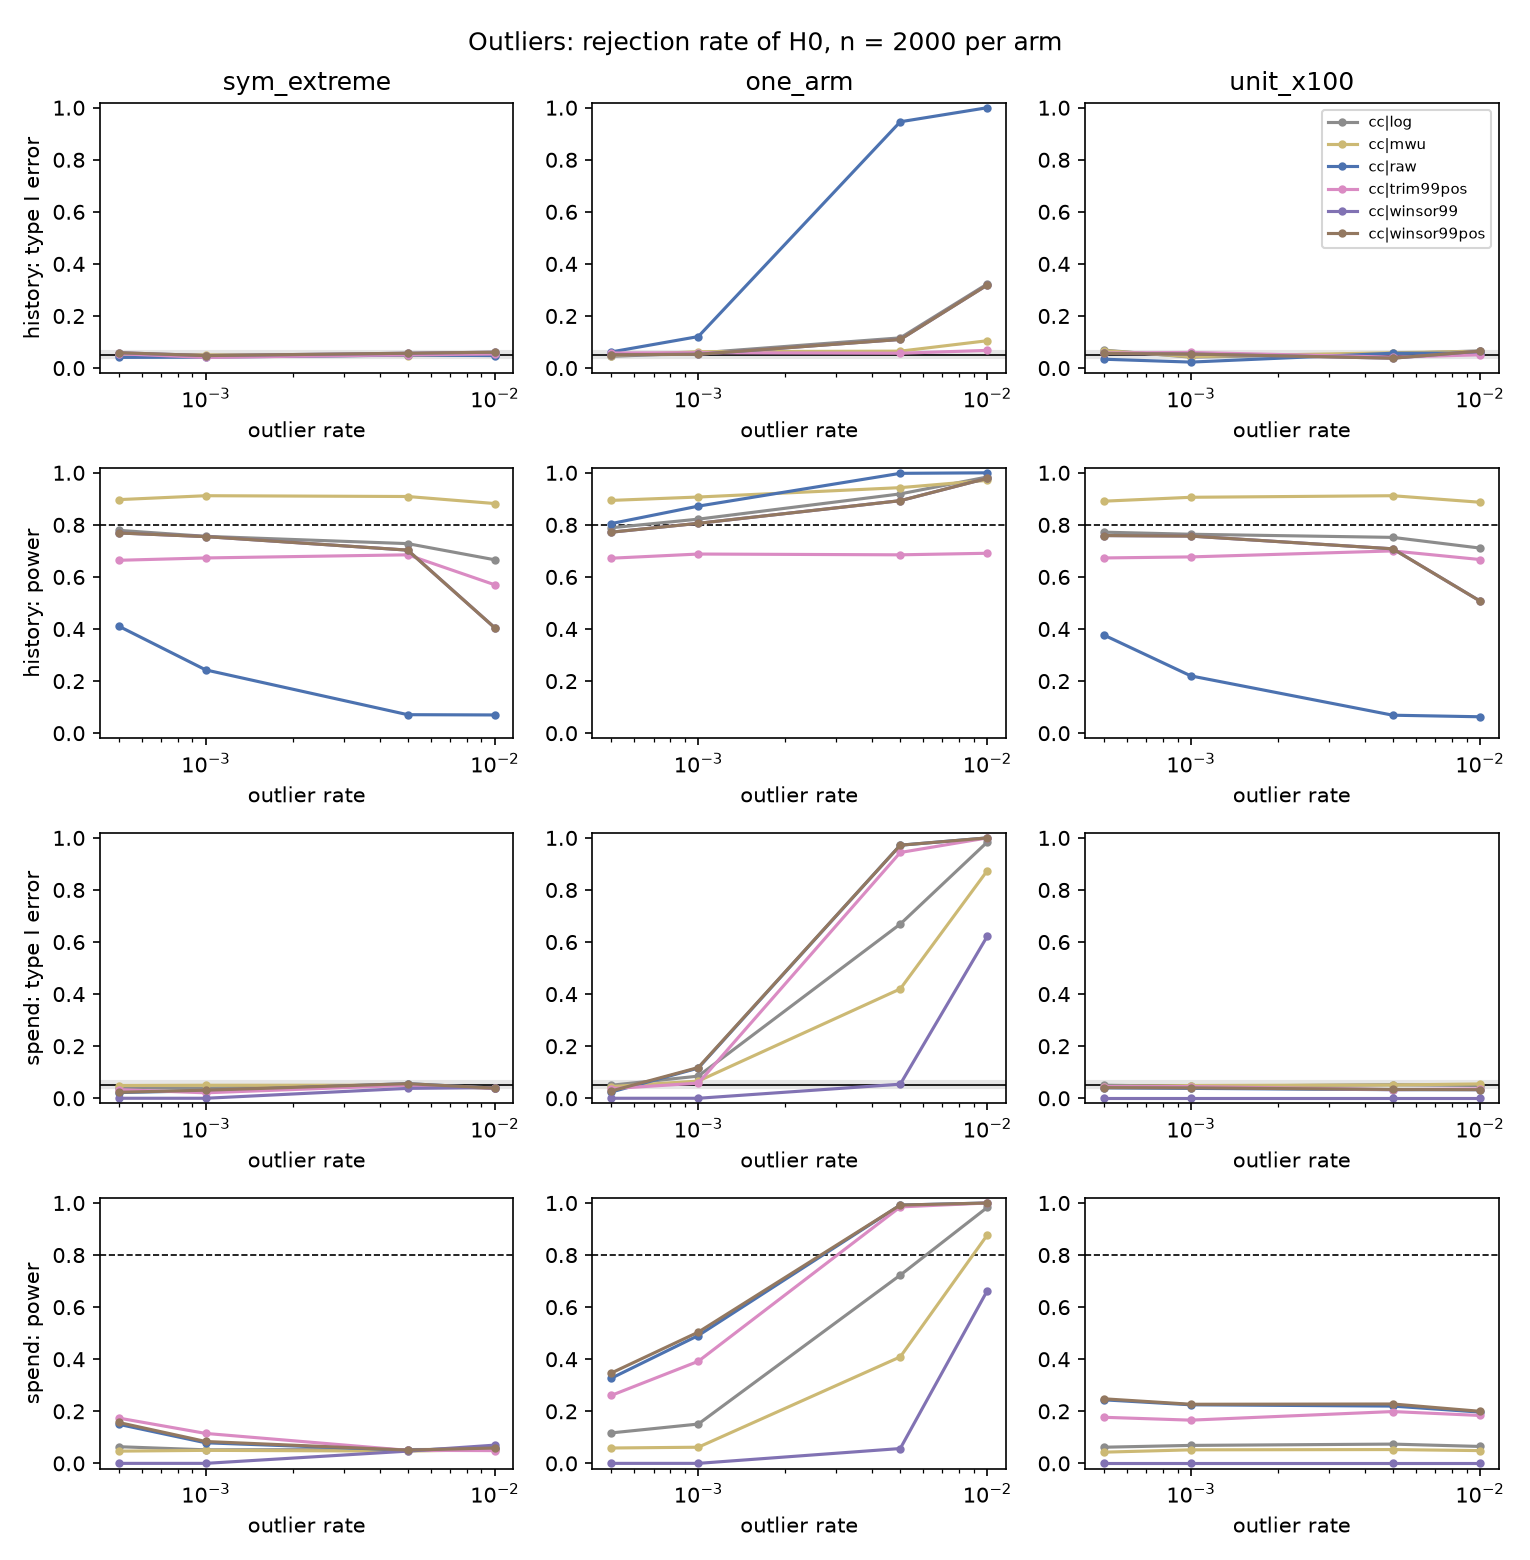

In [9]:
display(Image("figures/fig4_outliers_power.png"))

## 7. Experiment 3: sample size (Figure 5)

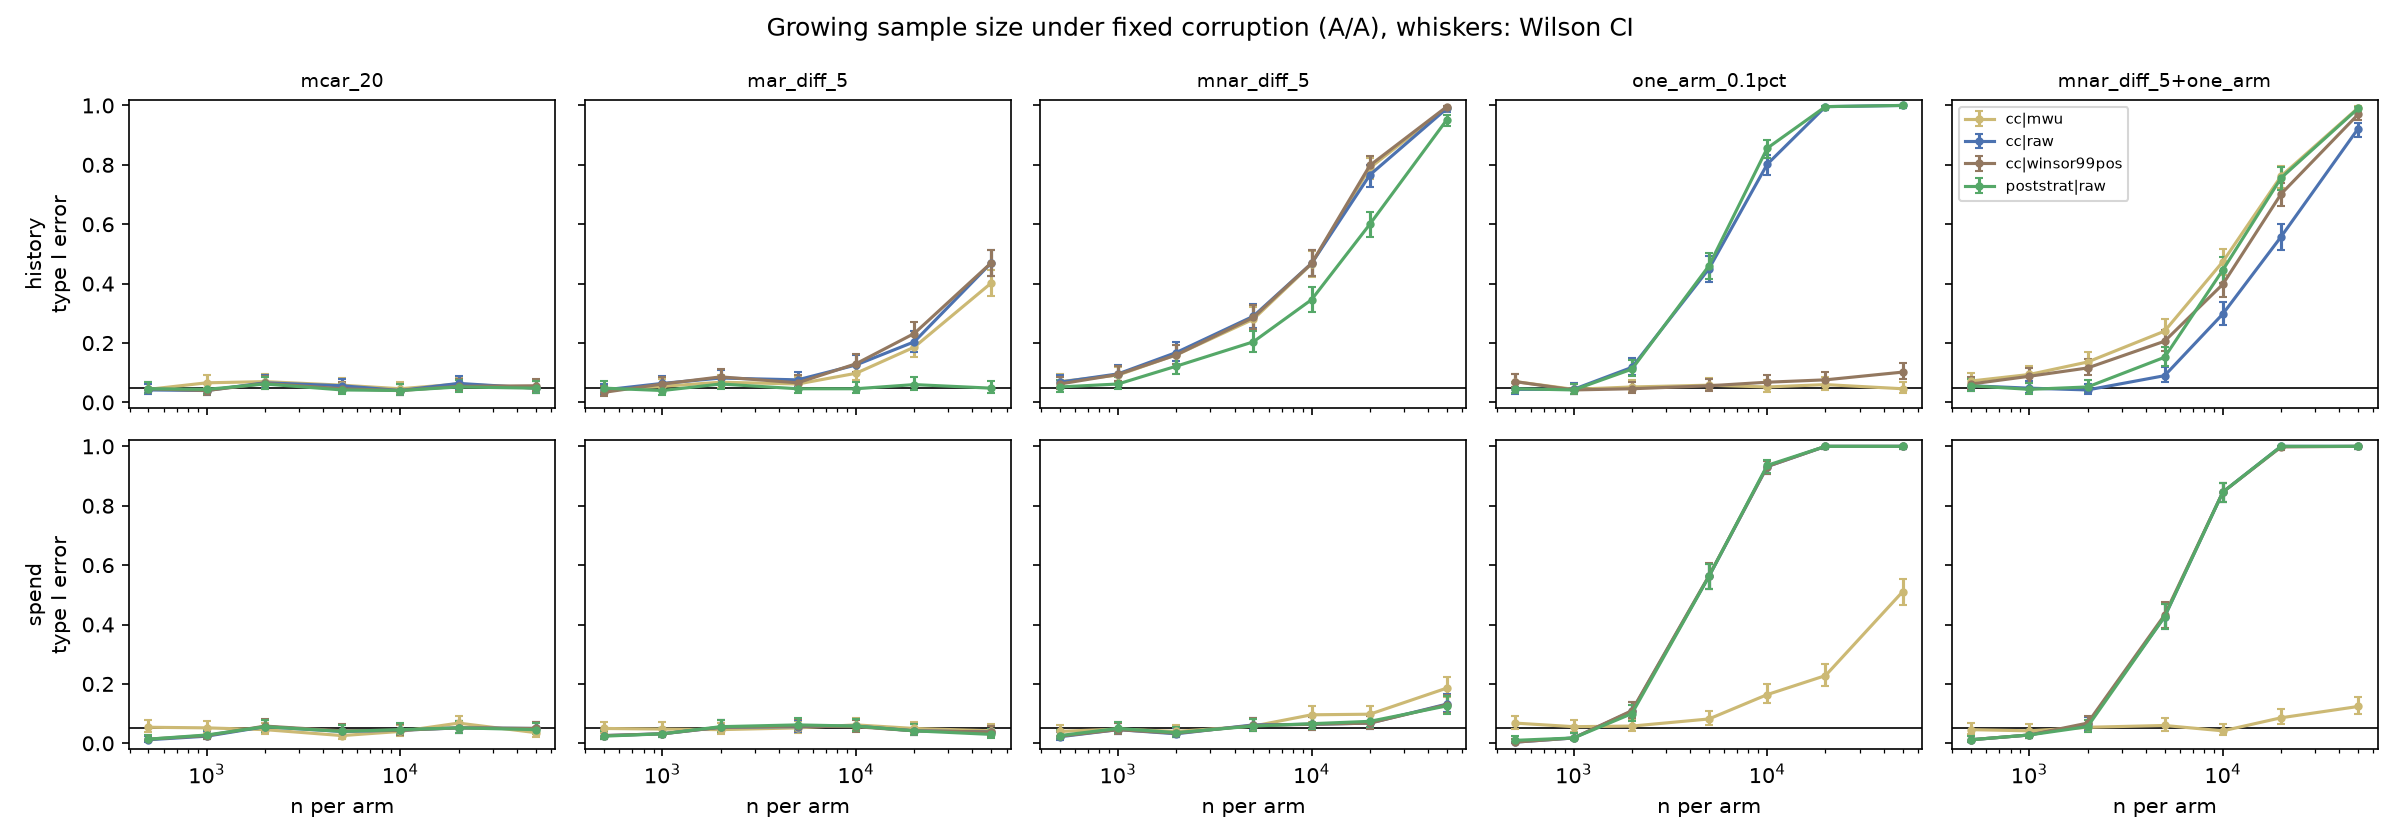

In [10]:
display(Image("figures/fig5_sample_size.png"))

## 8. Experiment 4: real Hillstrom comparison (Figure 6)

,arm,metric,nA,nB,meanA,meanB,lift_pct,welch_diff,welch_lo,welch_hi,welch_p,boot_lo,boot_hi,mwu_p,hedges_g,z_lo,z_hi,z_p
0,Mens E-Mail,visit,21306,21307,0.1062,0.1828,72.1405,0.0766,0.0700,0.0832,0.0000,0.0701,0.0835,0.0000,0.2192,0.0700,0.0832,0.0000
1,Mens E-Mail,conversion,21306,21307,0.0057,0.0125,118.8422,0.0068,0.0050,0.0086,0.0000,0.0050,0.0085,0.0000,0.0716,0.0050,0.0086,0.0000
2,Mens E-Mail,spend,21306,21307,0.6528,1.4226,117.9289,0.7698,0.4851,1.0545,0.0000,0.4693,1.0681,0.0000,0.0513,NaN,NaN,NaN
3,Womens E-Mail,visit,21306,21387,0.1062,0.1514,42.6055,0.0452,0.0389,0.0516,0.0000,0.0390,0.0513,0.0000,0.1353,0.0389,0.0516,0.0000
4,Womens E-Mail,conversion,21306,21387,0.0057,0.0088,54.3313,0.0031,0.0015,0.0047,0.0002,0.0015,0.0048,0.0002,0.0366,0.0015,0.0047,0.0002
5,Womens E-Mail,spend,21306,21387,0.6528,1.0772,65.0152,0.4244,0.1690,0.6799,0.0011,0.1749,0.6827,0.0002,0.0315,NaN,NaN,NaN


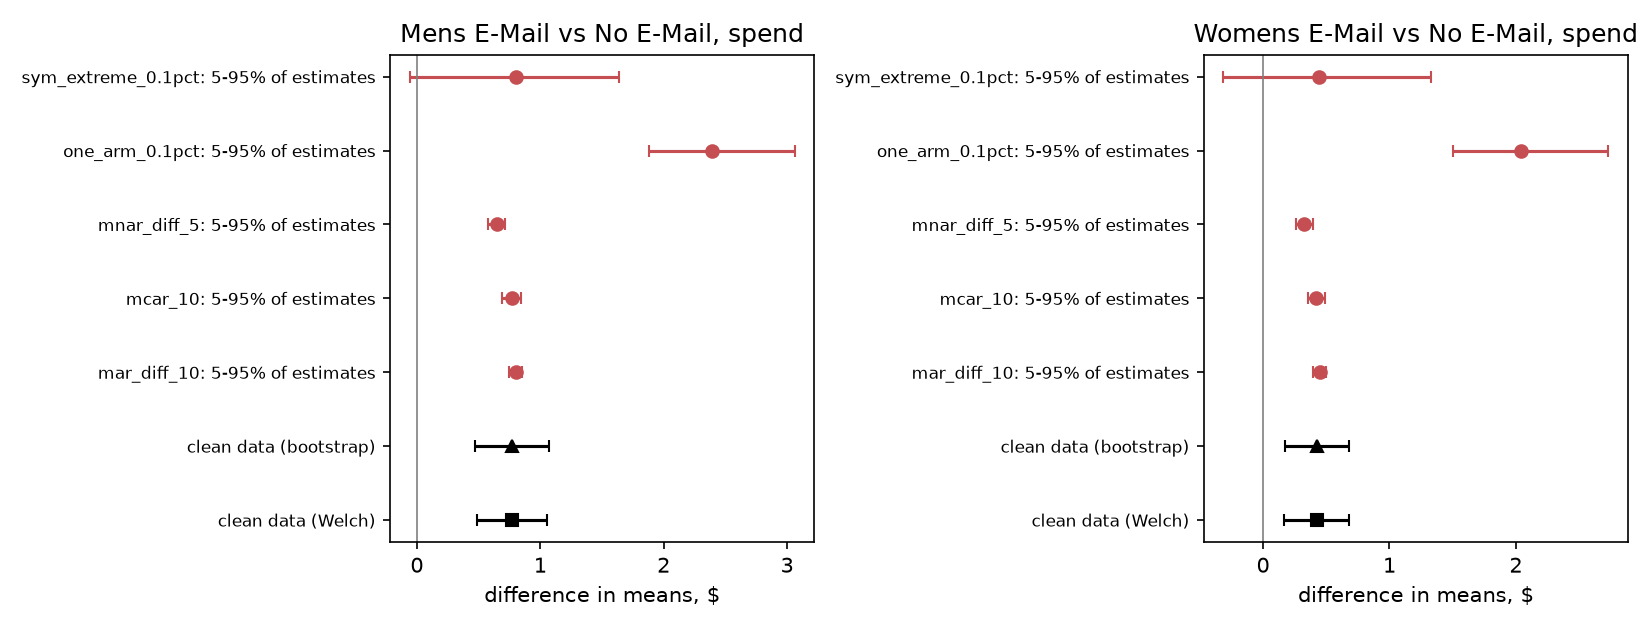

In [11]:
display(pd.read_csv("results/exp4_clean.csv").round(4))
display(Image("figures/fig6_case_forest.png"))

## 9. Decision flips (Figure 7)

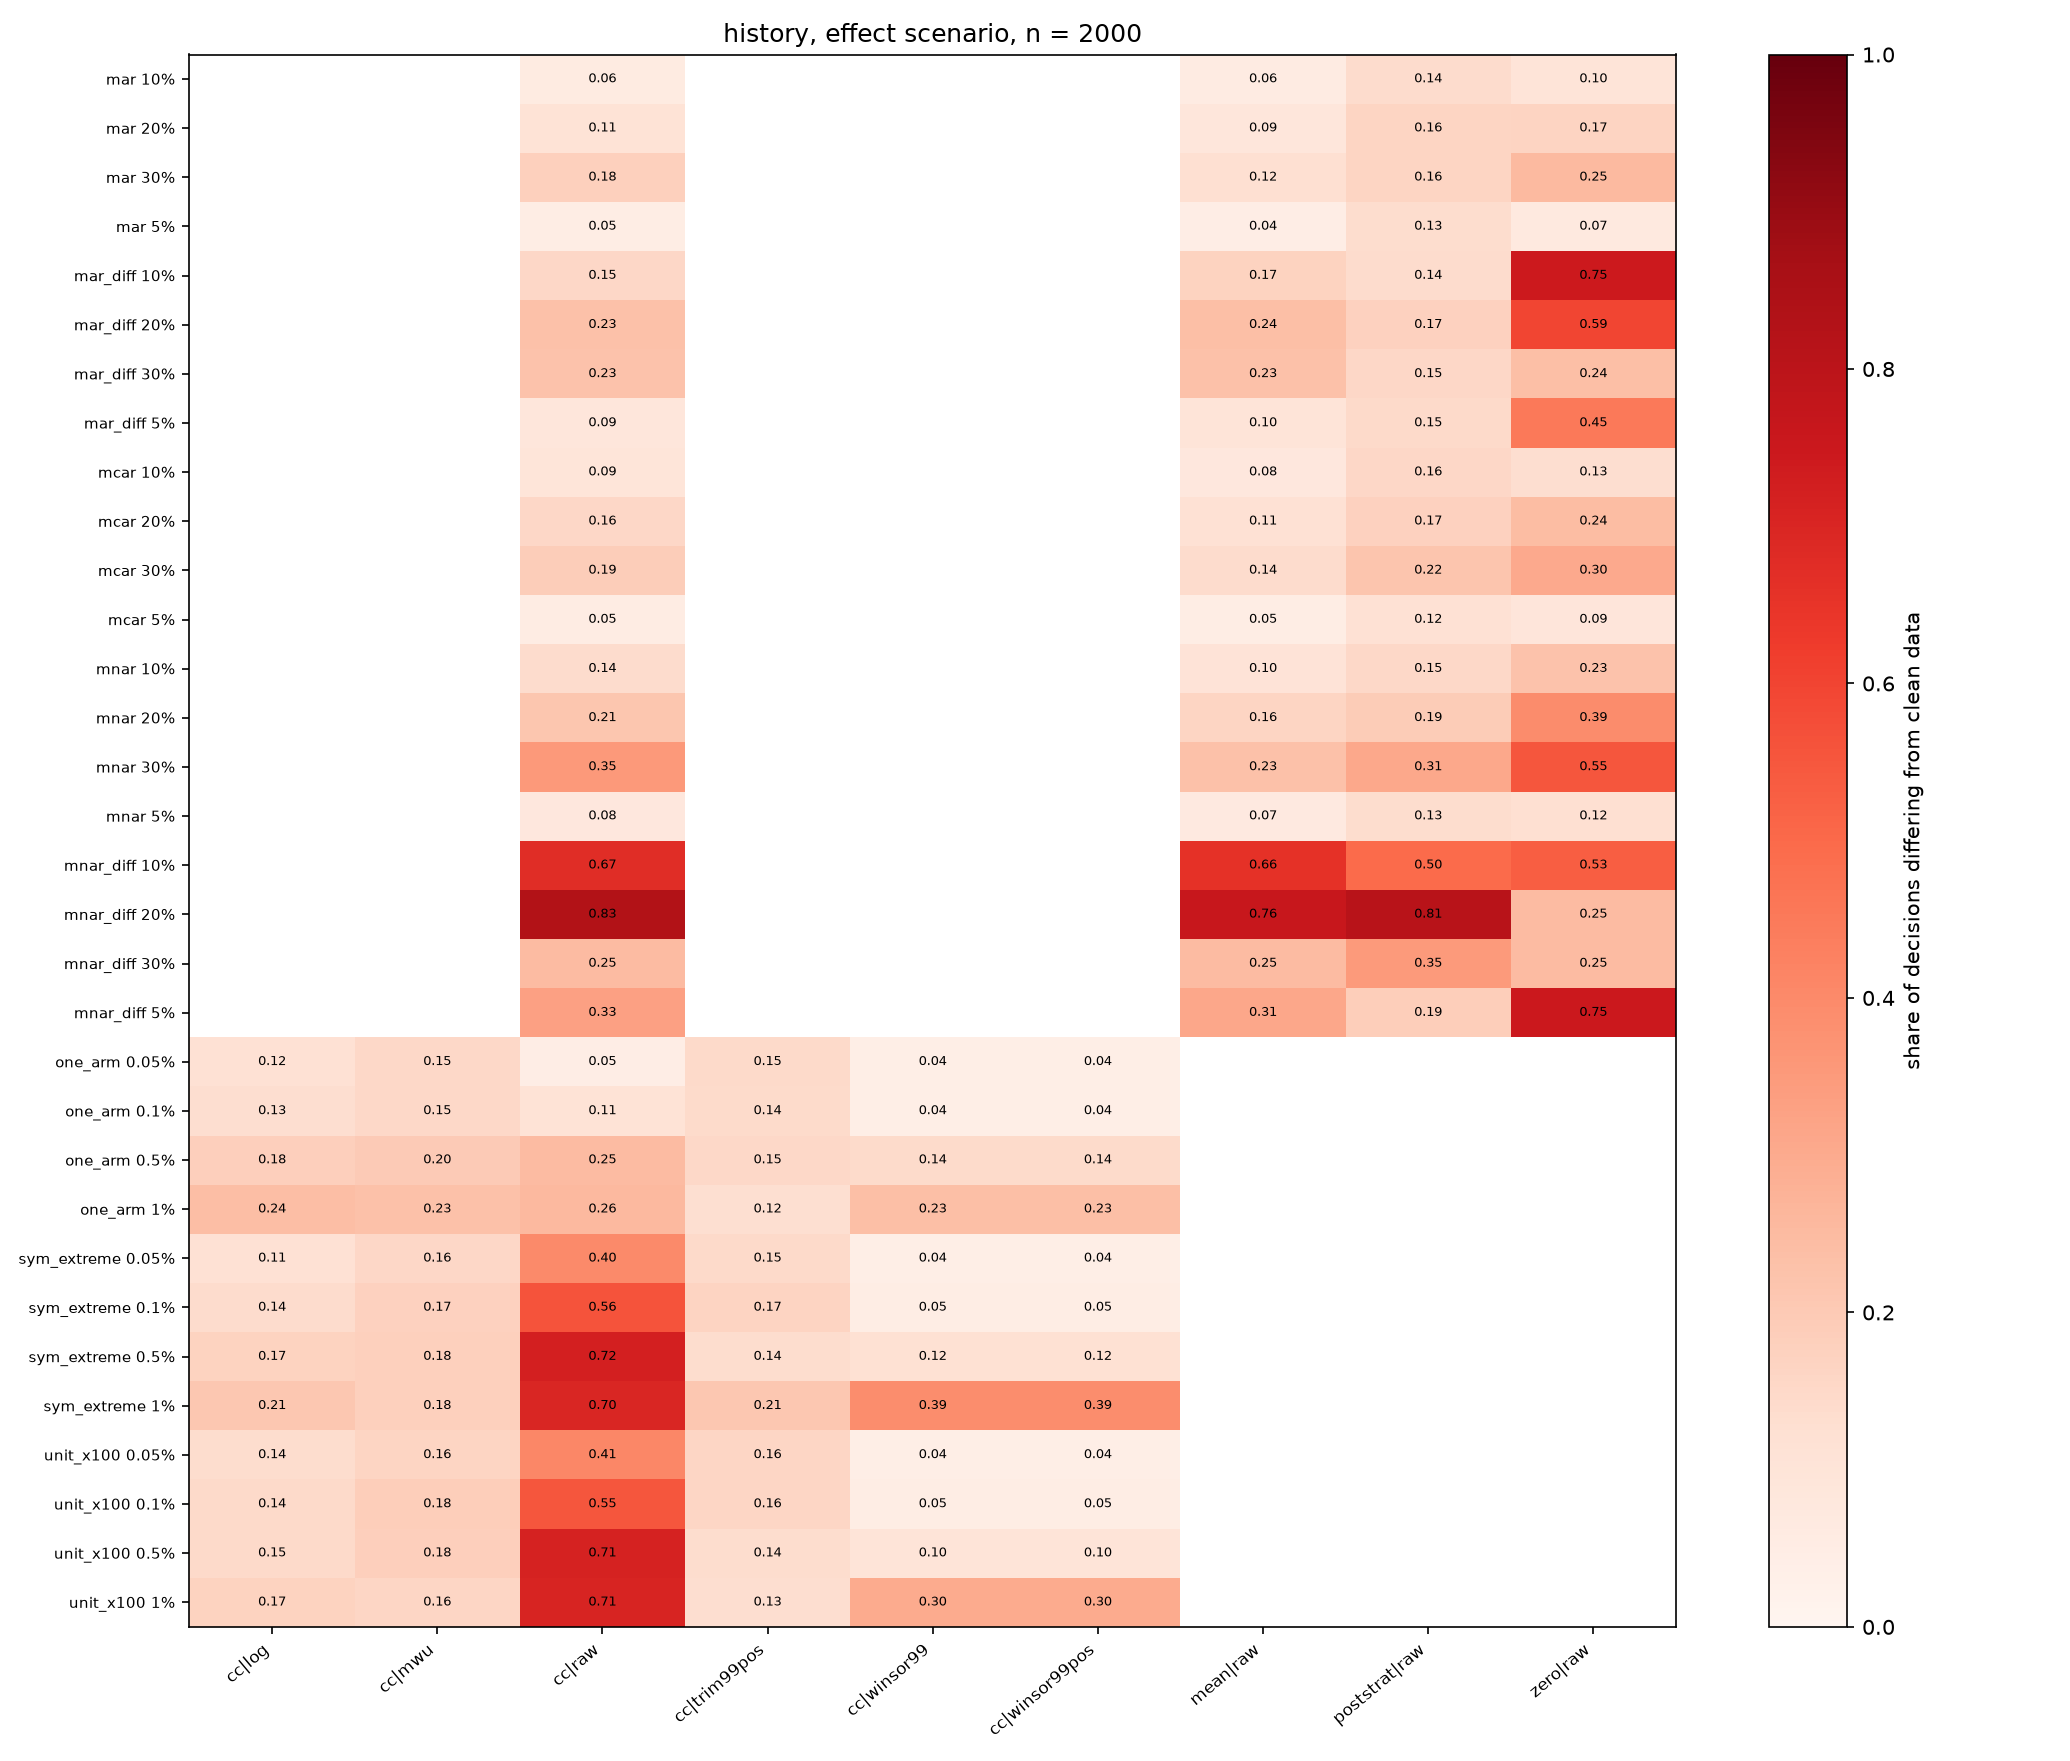

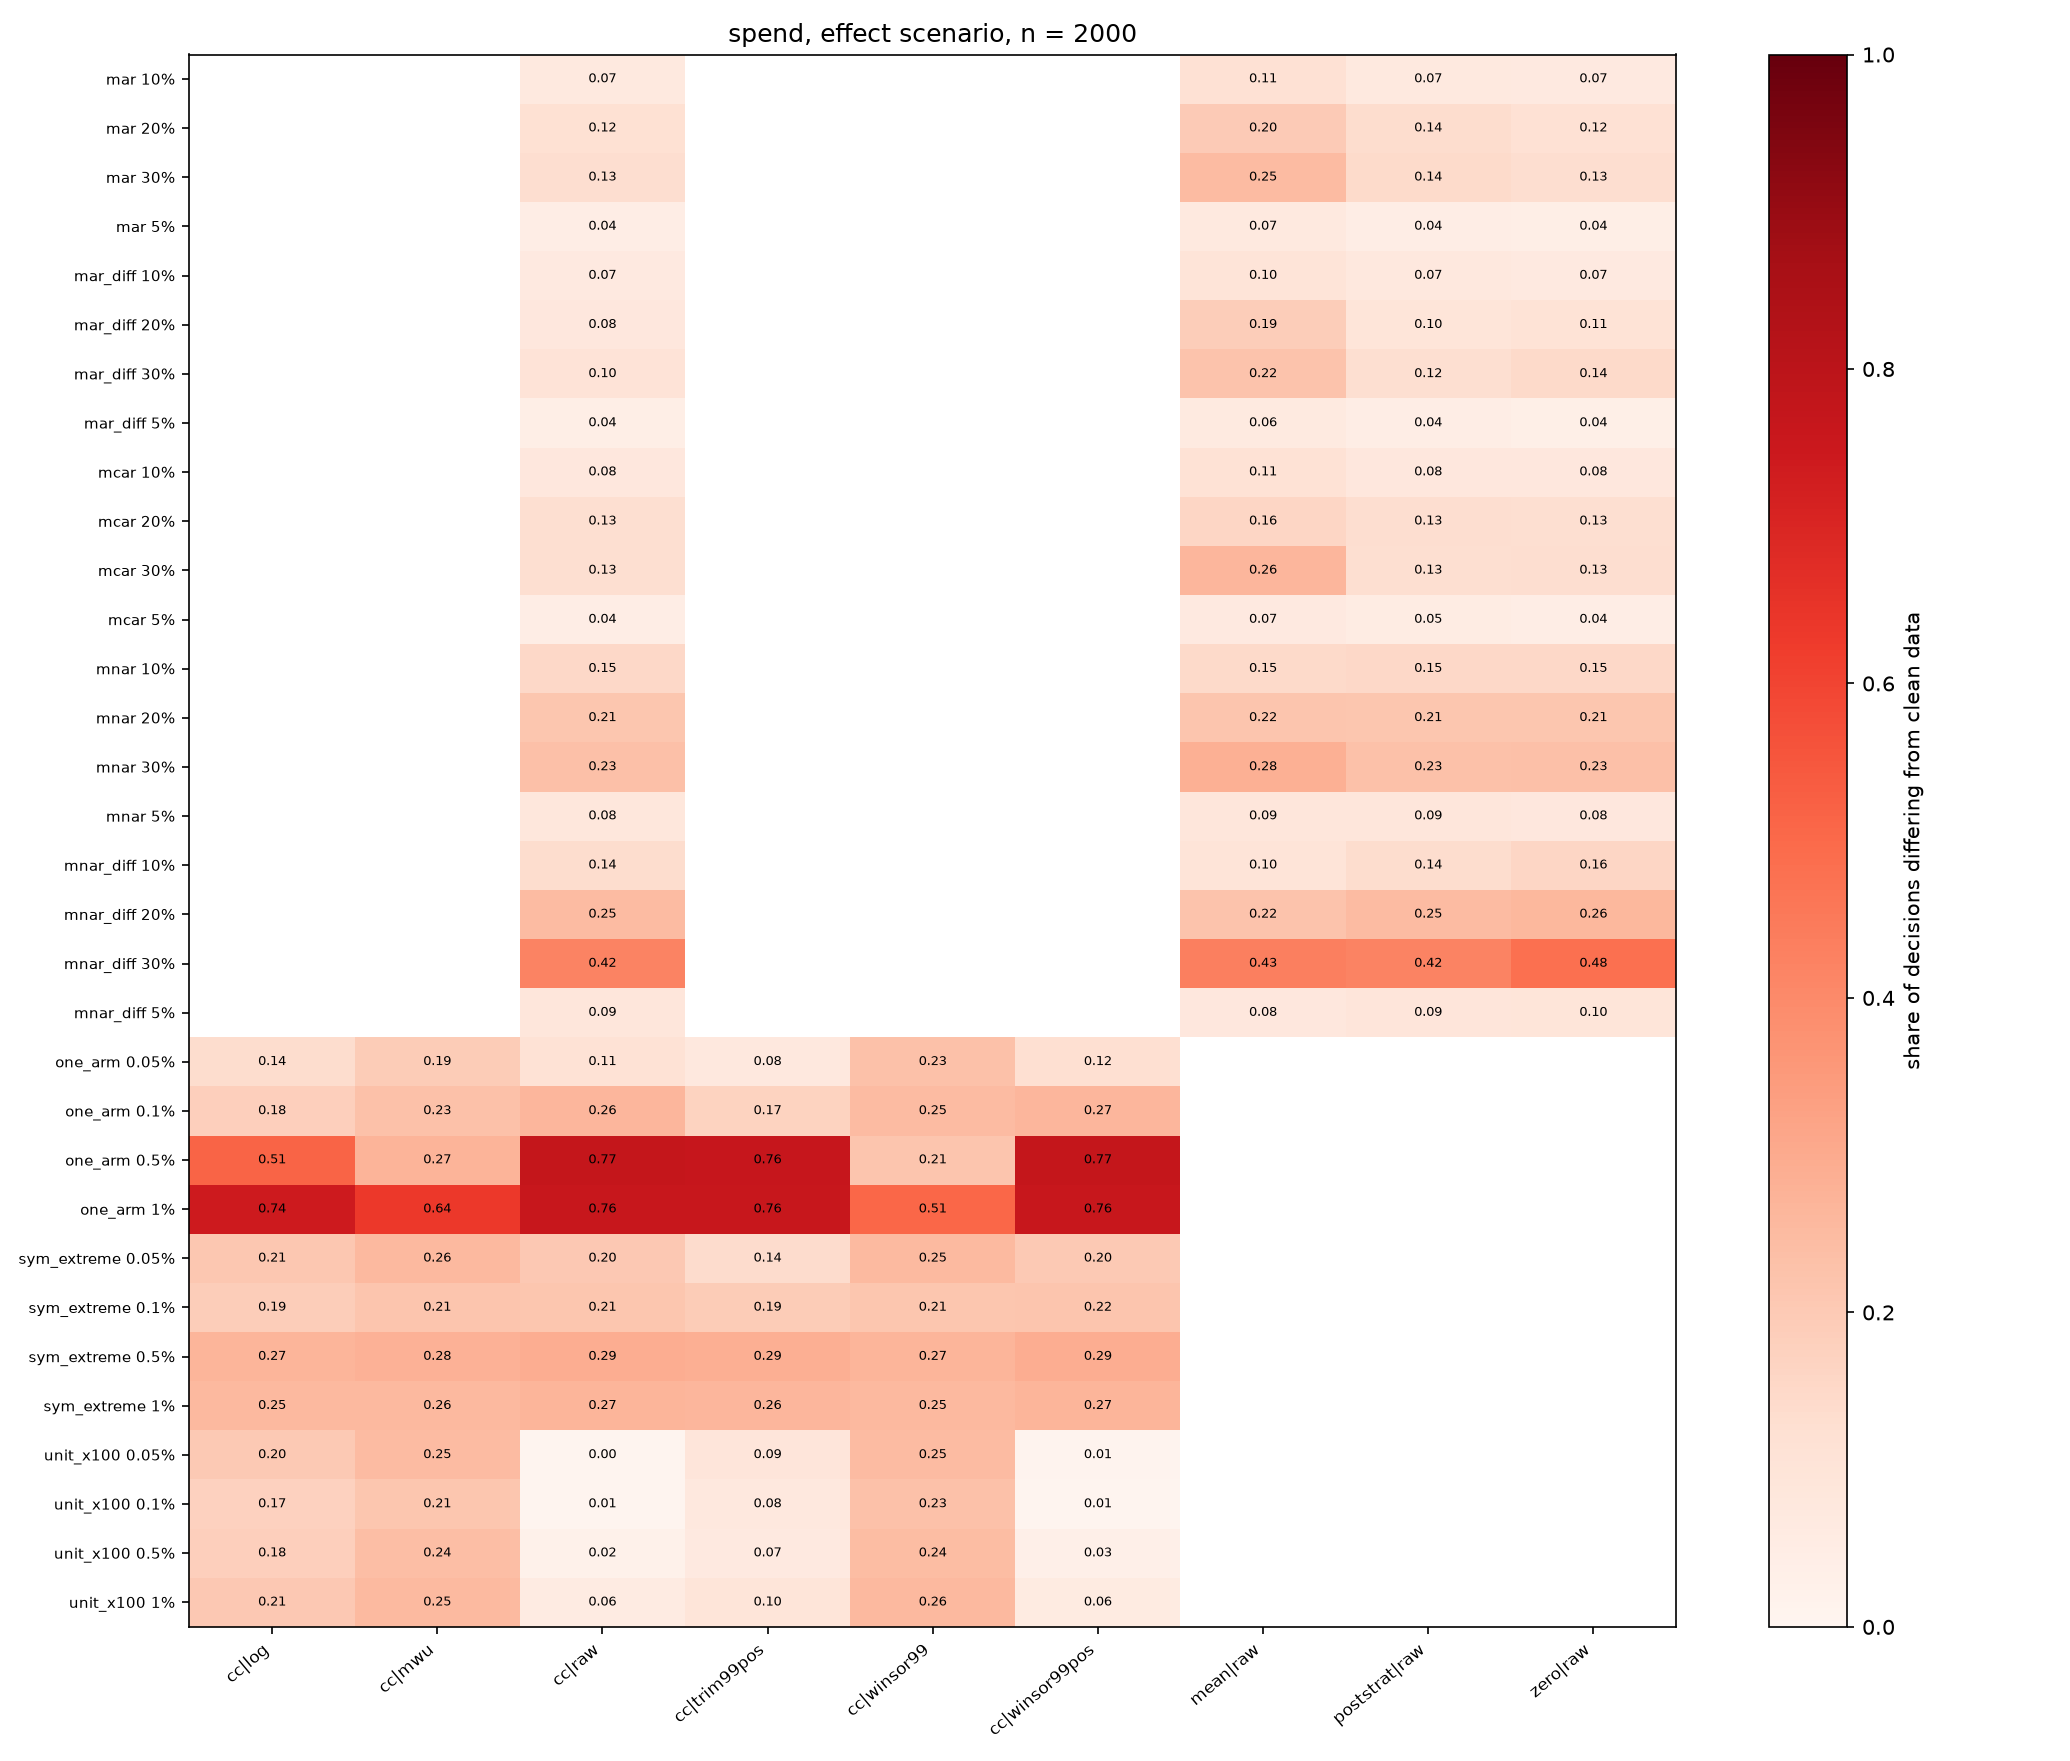

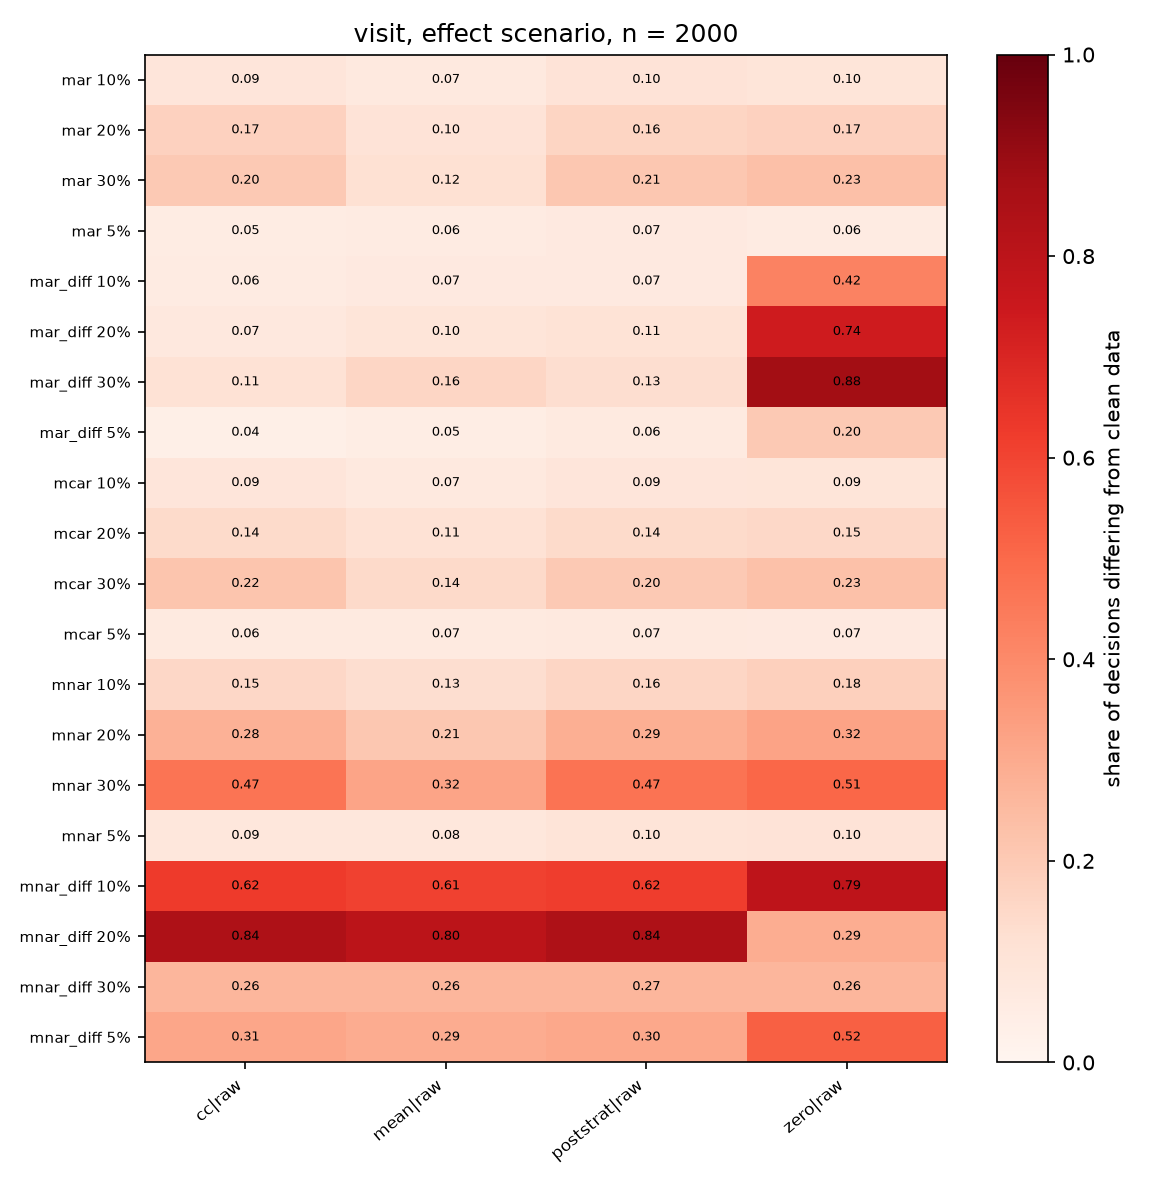

In [12]:
for p in sorted(pathlib.Path("figures").glob("fig7_flip_heatmap_*.png")):
    display(Image(str(p)))

## 10. All summary tables

The same text is in `results/tables.md`.

In [13]:
display(Markdown(pathlib.Path("results/tables.md").read_text(encoding="utf-8")))

## Table T1. Descriptive statistics of metrics (control group)

| metric     |     n |    mean |      sd |   skew |   share_zero |     q99 |     q999 |   q99_pos |     max |
|:-----------|------:|--------:|--------:|-------:|-------------:|--------:|---------:|----------:|--------:|
| history    | 21306 | 240.883 | 252.739 |  2.36  |        0     | 1191.89 | 1865.14  |  1191.89  | 3345.93 |
| visit      | 21306 |   0.106 |   0.308 |  2.557 |        0.894 |    1    |    1     |     1     |    1    |
| conversion | 21306 |   0.006 |   0.075 | 13.101 |        0.994 |    0    |    1     |     1     |    1    |
| spend      | 21306 |   0.653 |  11.588 | 26.366 |        0.994 |    0    |  165.852 |   487.643 |  499    |

## Table T2. Type I error under missingness (A/A, n = 2000)

| metric   | mech      |   rate |   cc|raw |   mean|raw |   poststrat|raw |   zero|raw |
|:---------|:----------|-------:|---------:|-----------:|----------------:|-----------:|
| history  | mar       |   0.05 |    0.048 |      0.06  |           0.052 |      0.048 |
| history  | mar       |   0.1  |    0.06  |      0.079 |           0.048 |      0.052 |
| history  | mar       |   0.2  |    0.048 |      0.108 |           0.047 |      0.044 |
| history  | mar       |   0.3  |    0.047 |      0.174 |           0.047 |      0.049 |
| history  | mar_diff  |   0.05 |    0.07  |      0.079 |           0.048 |      0.217 |
| history  | mar_diff  |   0.1  |    0.12  |      0.143 |           0.053 |      0.636 |
| history  | mar_diff  |   0.2  |    0.282 |      0.344 |           0.043 |      0.999 |
| history  | mar_diff  |   0.3  |    0.508 |      0.639 |           0.042 |      1     |
| history  | mcar      |   0.05 |    0.045 |      0.055 |           0.05  |      0.041 |
| history  | mcar      |   0.1  |    0.047 |      0.07  |           0.053 |      0.043 |
| history  | mcar      |   0.2  |    0.044 |      0.108 |           0.051 |      0.053 |
| history  | mcar      |   0.3  |    0.052 |      0.198 |           0.054 |      0.066 |
| history  | mnar      |   0.05 |    0.049 |      0.061 |           0.055 |      0.051 |
| history  | mnar      |   0.1  |    0.046 |      0.066 |           0.051 |      0.047 |
| history  | mnar      |   0.2  |    0.05  |      0.128 |           0.056 |      0.048 |
| history  | mnar      |   0.3  |    0.043 |      0.146 |           0.043 |      0.04  |
| history  | mnar_diff |   0.05 |    0.122 |      0.138 |           0.11  |      0.647 |
| history  | mnar_diff |   0.1  |    0.415 |      0.45  |           0.307 |      0.994 |
| history  | mnar_diff |   0.2  |    0.978 |      0.984 |           0.897 |      1     |
| history  | mnar_diff |   0.3  |    1     |      1     |           1     |      1     |
| spend    | mar       |   0.05 |    0.049 |      0.061 |           0.051 |      0.049 |
| spend    | mar       |   0.1  |    0.048 |      0.08  |           0.046 |      0.047 |
| spend    | mar       |   0.2  |    0.036 |      0.105 |           0.033 |      0.034 |
| spend    | mar       |   0.3  |    0.032 |      0.178 |           0.039 |      0.032 |
| spend    | mar_diff  |   0.05 |    0.044 |      0.047 |           0.045 |      0.045 |
| spend    | mar_diff  |   0.1  |    0.046 |      0.059 |           0.043 |      0.047 |
| spend    | mar_diff  |   0.2  |    0.048 |      0.087 |           0.054 |      0.065 |
| spend    | mar_diff  |   0.3  |    0.029 |      0.078 |           0.033 |      0.067 |
| spend    | mcar      |   0.05 |    0.046 |      0.063 |           0.049 |      0.047 |
| spend    | mcar      |   0.1  |    0.043 |      0.064 |           0.045 |      0.043 |
| spend    | mcar      |   0.2  |    0.039 |      0.118 |           0.038 |      0.04  |
| spend    | mcar      |   0.3  |    0.042 |      0.17  |           0.043 |      0.045 |
| spend    | mnar      |   0.05 |    0.055 |      0.068 |           0.052 |      0.054 |
| spend    | mnar      |   0.1  |    0.044 |      0.078 |           0.048 |      0.045 |
| spend    | mnar      |   0.2  |    0.038 |      0.127 |           0.036 |      0.038 |
| spend    | mnar      |   0.3  |    0.012 |      0.171 |           0.016 |      0.012 |
| spend    | mnar_diff |   0.05 |    0.049 |      0.049 |           0.048 |      0.05  |
| spend    | mnar_diff |   0.1  |    0.064 |      0.076 |           0.068 |      0.078 |
| spend    | mnar_diff |   0.2  |    0.148 |      0.167 |           0.149 |      0.213 |
| spend    | mnar_diff |   0.3  |    0.45  |      0.488 |           0.445 |      0.566 |
| visit    | mar       |   0.05 |    0.059 |      0.074 |           0.061 |      0.053 |
| visit    | mar       |   0.1  |    0.049 |      0.069 |           0.049 |      0.047 |
| visit    | mar       |   0.2  |    0.042 |      0.111 |           0.034 |      0.044 |
| visit    | mar       |   0.3  |    0.058 |      0.163 |           0.054 |      0.059 |
| visit    | mar_diff  |   0.05 |    0.052 |      0.056 |           0.055 |      0.084 |
| visit    | mar_diff  |   0.1  |    0.055 |      0.076 |           0.054 |      0.157 |
| visit    | mar_diff  |   0.2  |    0.057 |      0.088 |           0.047 |      0.475 |
| visit    | mar_diff  |   0.3  |    0.062 |      0.136 |           0.047 |      0.878 |
| visit    | mcar      |   0.05 |    0.052 |      0.063 |           0.05  |      0.051 |
| visit    | mcar      |   0.1  |    0.053 |      0.085 |           0.052 |      0.055 |
| visit    | mcar      |   0.2  |    0.04  |      0.099 |           0.04  |      0.036 |
| visit    | mcar      |   0.3  |    0.041 |      0.172 |           0.045 |      0.049 |
| visit    | mnar      |   0.05 |    0.037 |      0.045 |           0.036 |      0.038 |
| visit    | mnar      |   0.1  |    0.047 |      0.075 |           0.058 |      0.047 |
| visit    | mnar      |   0.2  |    0.058 |      0.117 |           0.052 |      0.051 |
| visit    | mnar      |   0.3  |    0.054 |      0.173 |           0.057 |      0.056 |
| visit    | mnar_diff |   0.05 |    0.092 |      0.096 |           0.087 |      0.241 |
| visit    | mnar_diff |   0.1  |    0.357 |      0.394 |           0.361 |      0.767 |
| visit    | mnar_diff |   0.2  |    0.965 |      0.981 |           0.964 |      1     |
| visit    | mnar_diff |   0.3  |    1     |      1     |           1     |      1     |

## Table T3. Power under missingness (effect at MDE, n = 2000)

| metric   | mech      |   rate |   cc|raw |   mean|raw |   poststrat|raw |   zero|raw |
|:---------|:----------|-------:|---------:|-----------:|----------------:|-----------:|
| history  | mar       |   0.05 |    0.761 |      0.784 |           0.865 |      0.736 |
| history  | mar       |   0.1  |    0.72  |      0.78  |           0.844 |      0.685 |
| history  | mar       |   0.2  |    0.662 |      0.797 |           0.812 |      0.608 |
| history  | mar       |   0.3  |    0.599 |      0.79  |           0.759 |      0.522 |
| history  | mar_diff  |   0.05 |    0.832 |      0.845 |           0.856 |      0.291 |
| history  | mar_diff  |   0.1  |    0.926 |      0.944 |           0.881 |      0.045 |
| history  | mar_diff  |   0.2  |    0.978 |      0.989 |           0.866 |      0.654 |
| history  | mar_diff  |   0.3  |    0.992 |      0.995 |           0.864 |      0.998 |
| history  | mcar      |   0.05 |    0.76  |      0.786 |           0.856 |      0.727 |
| history  | mcar      |   0.1  |    0.729 |      0.786 |           0.857 |      0.693 |
| history  | mcar      |   0.2  |    0.645 |      0.759 |           0.79  |      0.565 |
| history  | mcar      |   0.3  |    0.619 |      0.82  |           0.746 |      0.525 |
| history  | mnar      |   0.05 |    0.742 |      0.766 |           0.843 |      0.69  |
| history  | mnar      |   0.1  |    0.678 |      0.743 |           0.802 |      0.586 |
| history  | mnar      |   0.2  |    0.628 |      0.757 |           0.741 |      0.421 |
| history  | mnar      |   0.3  |    0.466 |      0.728 |           0.601 |      0.224 |
| history  | mnar_diff |   0.05 |    0.429 |      0.45  |           0.646 |      0.054 |
| history  | mnar_diff |   0.1  |    0.121 |      0.142 |           0.287 |      0.689 |
| history  | mnar_diff |   0.2  |    0.386 |      0.48  |           0.092 |      1     |
| history  | mnar_diff |   0.3  |    0.999 |      0.999 |           0.9   |      1     |
| spend    | mar       |   0.05 |    0.229 |      0.289 |           0.236 |      0.229 |
| spend    | mar       |   0.1  |    0.201 |      0.317 |           0.196 |      0.202 |
| spend    | mar       |   0.2  |    0.197 |      0.413 |           0.172 |      0.192 |
| spend    | mar       |   0.3  |    0.167 |      0.462 |           0.147 |      0.171 |
| spend    | mar_diff  |   0.05 |    0.228 |      0.273 |           0.225 |      0.209 |
| spend    | mar_diff  |   0.1  |    0.227 |      0.307 |           0.217 |      0.189 |
| spend    | mar_diff  |   0.2  |    0.192 |      0.399 |           0.168 |      0.133 |
| spend    | mar_diff  |   0.3  |    0.161 |      0.421 |           0.121 |      0.091 |
| spend    | mcar      |   0.05 |    0.234 |      0.289 |           0.234 |      0.234 |
| spend    | mcar      |   0.1  |    0.203 |      0.301 |           0.202 |      0.201 |
| spend    | mcar      |   0.2  |    0.181 |      0.385 |           0.177 |      0.181 |
| spend    | mcar      |   0.3  |    0.147 |      0.446 |           0.146 |      0.144 |
| spend    | mnar      |   0.05 |    0.194 |      0.24  |           0.195 |      0.192 |
| spend    | mnar      |   0.1  |    0.157 |      0.26  |           0.152 |      0.155 |
| spend    | mnar      |   0.2  |    0.071 |      0.243 |           0.075 |      0.073 |
| spend    | mnar      |   0.3  |    0.016 |      0.205 |           0.017 |      0.016 |
| spend    | mnar_diff |   0.05 |    0.171 |      0.203 |           0.165 |      0.159 |
| spend    | mnar_diff |   0.1  |    0.096 |      0.151 |           0.096 |      0.072 |
| spend    | mnar_diff |   0.2  |    0.045 |      0.083 |           0.045 |      0.053 |
| spend    | mnar_diff |   0.3  |    0.224 |      0.254 |           0.222 |      0.301 |
| visit    | mar       |   0.05 |    0.725 |      0.767 |           0.732 |      0.719 |
| visit    | mar       |   0.1  |    0.719 |      0.782 |           0.724 |      0.711 |
| visit    | mar       |   0.2  |    0.642 |      0.781 |           0.653 |      0.632 |
| visit    | mar       |   0.3  |    0.608 |      0.796 |           0.61  |      0.573 |
| visit    | mar_diff  |   0.05 |    0.784 |      0.807 |           0.761 |      0.572 |
| visit    | mar_diff  |   0.1  |    0.78  |      0.811 |           0.759 |      0.333 |
| visit    | mar_diff  |   0.2  |    0.821 |      0.873 |           0.732 |      0.076 |
| visit    | mar_diff  |   0.3  |    0.775 |      0.871 |           0.642 |      0.184 |
| visit    | mcar      |   0.05 |    0.727 |      0.759 |           0.735 |      0.728 |
| visit    | mcar      |   0.1  |    0.728 |      0.785 |           0.729 |      0.721 |
| visit    | mcar      |   0.2  |    0.67  |      0.799 |           0.678 |      0.66  |
| visit    | mcar      |   0.3  |    0.588 |      0.798 |           0.605 |      0.574 |
| visit    | mnar      |   0.05 |    0.725 |      0.745 |           0.72  |      0.71  |
| visit    | mnar      |   0.1  |    0.657 |      0.725 |           0.656 |      0.637 |
| visit    | mnar      |   0.2  |    0.527 |      0.667 |           0.521 |      0.479 |
| visit    | mnar      |   0.3  |    0.333 |      0.574 |           0.326 |      0.293 |
| visit    | mnar_diff |   0.05 |    0.419 |      0.44  |           0.428 |      0.213 |
| visit    | mnar_diff |   0.1  |    0.128 |      0.145 |           0.135 |      0.065 |
| visit    | mnar_diff |   0.2  |    0.329 |      0.408 |           0.319 |      0.948 |
| visit    | mnar_diff |   0.3  |    0.998 |      1     |           0.997 |      1     |

## Table T4. Coverage of the true effect by the 95% CI (n = 2000)

| metric   | mech      |   rate |   cc|raw |   mean|raw |   poststrat|raw |   zero|raw |
|:---------|:----------|-------:|---------:|-----------:|----------------:|-----------:|
| history  | mar       |   0.05 |    0.955 |      0.94  |           0.966 |      0.961 |
| history  | mar       |   0.1  |    0.951 |      0.919 |           0.946 |      0.946 |
| history  | mar       |   0.2  |    0.948 |      0.881 |           0.954 |      0.924 |
| history  | mar       |   0.3  |    0.944 |      0.814 |           0.939 |      0.884 |
| history  | mar_diff  |   0.05 |    0.934 |      0.929 |           0.939 |      0.756 |
| history  | mar_diff  |   0.1  |    0.904 |      0.876 |           0.953 |      0.335 |
| history  | mar_diff  |   0.2  |    0.7   |      0.622 |           0.941 |      0.002 |
| history  | mar_diff  |   0.3  |    0.454 |      0.301 |           0.945 |      0     |
| history  | mcar      |   0.05 |    0.946 |      0.927 |           0.945 |      0.936 |
| history  | mcar      |   0.1  |    0.948 |      0.925 |           0.95  |      0.937 |
| history  | mcar      |   0.2  |    0.953 |      0.89  |           0.942 |      0.901 |
| history  | mcar      |   0.3  |    0.949 |      0.836 |           0.952 |      0.876 |
| history  | mnar      |   0.05 |    0.955 |      0.938 |           0.948 |      0.938 |
| history  | mnar      |   0.1  |    0.939 |      0.902 |           0.946 |      0.897 |
| history  | mnar      |   0.2  |    0.915 |      0.835 |           0.929 |      0.716 |
| history  | mnar      |   0.3  |    0.86  |      0.663 |           0.887 |      0.334 |
| history  | mnar_diff |   0.05 |    0.847 |      0.836 |           0.887 |      0.279 |
| history  | mnar_diff |   0.1  |    0.517 |      0.462 |           0.638 |      0.001 |
| history  | mnar_diff |   0.2  |    0.009 |      0.004 |           0.06  |      0     |
| history  | mnar_diff |   0.3  |    0     |      0     |           0     |      0     |
| spend    | mar       |   0.05 |    0.892 |      0.887 |           0.897 |      0.886 |
| spend    | mar       |   0.1  |    0.903 |      0.881 |           0.903 |      0.886 |
| spend    | mar       |   0.2  |    0.891 |      0.839 |           0.883 |      0.843 |
| spend    | mar       |   0.3  |    0.915 |      0.799 |           0.9   |      0.817 |
| spend    | mar_diff  |   0.05 |    0.89  |      0.886 |           0.891 |      0.877 |
| spend    | mar_diff  |   0.1  |    0.892 |      0.876 |           0.883 |      0.867 |
| spend    | mar_diff  |   0.2  |    0.901 |      0.859 |           0.888 |      0.828 |
| spend    | mar_diff  |   0.3  |    0.894 |      0.825 |           0.873 |      0.749 |
| spend    | mcar      |   0.05 |    0.902 |      0.883 |           0.902 |      0.89  |
| spend    | mcar      |   0.1  |    0.9   |      0.869 |           0.901 |      0.868 |
| spend    | mcar      |   0.2  |    0.9   |      0.844 |           0.905 |      0.846 |
| spend    | mcar      |   0.3  |    0.888 |      0.77  |           0.888 |      0.762 |
| spend    | mnar      |   0.05 |    0.891 |      0.878 |           0.89  |      0.877 |
| spend    | mnar      |   0.1  |    0.837 |      0.811 |           0.837 |      0.806 |
| spend    | mnar      |   0.2  |    0.702 |      0.617 |           0.7   |      0.577 |
| spend    | mnar      |   0.3  |    0.38  |      0.294 |           0.382 |      0.25  |
| spend    | mnar_diff |   0.05 |    0.86  |      0.853 |           0.862 |      0.843 |
| spend    | mnar_diff |   0.1  |    0.814 |      0.787 |           0.81  |      0.749 |
| spend    | mnar_diff |   0.2  |    0.582 |      0.525 |           0.583 |      0.451 |
| spend    | mnar_diff |   0.3  |    0.236 |      0.183 |           0.238 |      0.121 |
| visit    | mar       |   0.05 |    0.949 |      0.937 |           0.957 |      0.942 |
| visit    | mar       |   0.1  |    0.951 |      0.927 |           0.951 |      0.945 |
| visit    | mar       |   0.2  |    0.961 |      0.886 |           0.96  |      0.919 |
| visit    | mar       |   0.3  |    0.946 |      0.823 |           0.948 |      0.848 |
| visit    | mar_diff  |   0.05 |    0.94  |      0.933 |           0.944 |      0.894 |
| visit    | mar_diff  |   0.1  |    0.948 |      0.934 |           0.947 |      0.774 |
| visit    | mar_diff  |   0.2  |    0.932 |      0.891 |           0.958 |      0.338 |
| visit    | mar_diff  |   0.3  |    0.936 |      0.861 |           0.946 |      0.029 |
| visit    | mcar      |   0.05 |    0.948 |      0.937 |           0.953 |      0.944 |
| visit    | mcar      |   0.1  |    0.955 |      0.925 |           0.96  |      0.945 |
| visit    | mcar      |   0.2  |    0.95  |      0.89  |           0.95  |      0.91  |
| visit    | mcar      |   0.3  |    0.954 |      0.82  |           0.95  |      0.845 |
| visit    | mnar      |   0.05 |    0.948 |      0.937 |           0.948 |      0.936 |
| visit    | mnar      |   0.1  |    0.937 |      0.903 |           0.936 |      0.897 |
| visit    | mnar      |   0.2  |    0.861 |      0.749 |           0.865 |      0.634 |
| visit    | mnar      |   0.3  |    0.621 |      0.38  |           0.63  |      0.098 |
| visit    | mnar_diff |   0.05 |    0.845 |      0.836 |           0.849 |      0.641 |
| visit    | mnar_diff |   0.1  |    0.543 |      0.502 |           0.547 |      0.108 |
| visit    | mnar_diff |   0.2  |    0.021 |      0.007 |           0.025 |      0     |
| visit    | mnar_diff |   0.3  |    0     |      0     |           0     |      0     |

## Table T5. Share of replications where the SRM check (p < 0.001) fired

| ('metric', '')   | ('mech', '')   |   ('aa', 0.05) |   ('aa', 0.1) |   ('aa', 0.2) |   ('aa', 0.3) |   ('effect', 0.05) |   ('effect', 0.1) |   ('effect', 0.2) |   ('effect', 0.3) |
|:-----------------|:---------------|---------------:|--------------:|--------------:|--------------:|-------------------:|------------------:|------------------:|------------------:|
| history          | mar            |              0 |         0     |             0 |             0 |                  0 |             0     |                 0 |                 0 |
| history          | mar_diff       |              0 |         0.421 |             1 |             1 |                  0 |             0.424 |                 1 |                 1 |
| history          | mcar           |              0 |         0     |             0 |             0 |                  0 |             0     |                 0 |                 0 |
| history          | mnar           |              0 |         0     |             0 |             0 |                  0 |             0     |                 0 |                 0 |
| history          | mnar_diff      |              0 |         0.435 |             1 |             1 |                  0 |             0.678 |                 1 |                 1 |
| spend            | mar            |              0 |         0     |             0 |             0 |                  0 |             0     |                 0 |                 0 |
| spend            | mar_diff       |              0 |         0.432 |             1 |             1 |                  0 |             0.408 |                 1 |                 1 |
| spend            | mcar           |              0 |         0     |             0 |             0 |                  0 |             0     |                 0 |                 0 |
| spend            | mnar           |              0 |         0     |             0 |             0 |                  0 |             0     |                 0 |                 0 |
| spend            | mnar_diff      |              0 |         0.422 |             1 |             1 |                  0 |             0.438 |                 1 |                 1 |
| visit            | mar            |              0 |         0     |             0 |             0 |                  0 |             0     |                 0 |                 0 |
| visit            | mar_diff       |              0 |         0.42  |             1 |             1 |                  0 |             0.437 |                 1 |                 1 |
| visit            | mcar           |              0 |         0     |             0 |             0 |                  0 |             0     |                 0 |                 0 |
| visit            | mnar           |              0 |         0     |             0 |             0 |                  0 |             0     |                 0 |                 0 |
| visit            | mnar_diff      |              0 |         0.432 |             1 |             1 |                  0 |             0.645 |                 1 |                 1 |

## Table T6. Type I error under outliers (n = 2000)

| metric   | out_type    |    eps |   cc|log |   cc|mwu |   cc|raw |   cc|trim99pos |   cc|winsor99 |   cc|winsor99pos |
|:---------|:------------|-------:|---------:|---------:|---------:|---------------:|--------------:|-----------------:|
| history  | one_arm     | 0.0005 |    0.045 |    0.048 |    0.062 |          0.058 |         0.051 |            0.051 |
| history  | one_arm     | 0.001  |    0.058 |    0.063 |    0.121 |          0.059 |         0.053 |            0.053 |
| history  | one_arm     | 0.005  |    0.116 |    0.065 |    0.946 |          0.057 |         0.11  |            0.11  |
| history  | one_arm     | 0.01   |    0.323 |    0.105 |    1     |          0.068 |         0.319 |            0.319 |
| history  | sym_extreme | 0.0005 |    0.05  |    0.053 |    0.041 |          0.055 |         0.059 |            0.059 |
| history  | sym_extreme | 0.001  |    0.045 |    0.051 |    0.042 |          0.041 |         0.048 |            0.048 |
| history  | sym_extreme | 0.005  |    0.049 |    0.048 |    0.05  |          0.051 |         0.057 |            0.057 |
| history  | sym_extreme | 0.01   |    0.051 |    0.052 |    0.048 |          0.054 |         0.061 |            0.061 |
| history  | unit_x100   | 0.0005 |    0.069 |    0.067 |    0.034 |          0.058 |         0.056 |            0.056 |
| history  | unit_x100   | 0.001  |    0.042 |    0.044 |    0.023 |          0.06  |         0.054 |            0.054 |
| history  | unit_x100   | 0.005  |    0.056 |    0.059 |    0.057 |          0.042 |         0.038 |            0.038 |
| history  | unit_x100   | 0.01   |    0.066 |    0.064 |    0.057 |          0.051 |         0.065 |            0.065 |
| spend    | one_arm     | 0.0005 |    0.05  |    0.045 |    0.024 |          0.037 |         0     |            0.028 |
| spend    | one_arm     | 0.001  |    0.085 |    0.066 |    0.116 |          0.058 |         0     |            0.118 |
| spend    | one_arm     | 0.005  |    0.669 |    0.42  |    0.972 |          0.944 |         0.054 |            0.972 |
| spend    | one_arm     | 0.01   |    0.984 |    0.874 |    1     |          1     |         0.622 |            1     |
| spend    | sym_extreme | 0.0005 |    0.04  |    0.049 |    0.022 |          0.033 |         0     |            0.023 |
| spend    | sym_extreme | 0.001  |    0.039 |    0.05  |    0.029 |          0.021 |         0     |            0.031 |
| spend    | sym_extreme | 0.005  |    0.05  |    0.05  |    0.056 |          0.05  |         0.038 |            0.056 |
| spend    | sym_extreme | 0.01   |    0.039 |    0.038 |    0.039 |          0.039 |         0.041 |            0.039 |
| spend    | unit_x100   | 0.0005 |    0.05  |    0.045 |    0.04  |          0.045 |         0     |            0.041 |
| spend    | unit_x100   | 0.001  |    0.046 |    0.049 |    0.038 |          0.045 |         0     |            0.04  |
| spend    | unit_x100   | 0.005  |    0.052 |    0.051 |    0.033 |          0.033 |         0     |            0.034 |
| spend    | unit_x100   | 0.01   |    0.049 |    0.055 |    0.033 |          0.036 |         0     |            0.033 |

## Table T7. Power under outliers (n = 2000)

| metric   | out_type    |    eps |   cc|log |   cc|mwu |   cc|raw |   cc|trim99pos |   cc|winsor99 |   cc|winsor99pos |
|:---------|:------------|-------:|---------:|---------:|---------:|---------------:|--------------:|-----------------:|
| history  | one_arm     | 0.0005 |    0.789 |    0.894 |    0.805 |          0.672 |         0.772 |            0.772 |
| history  | one_arm     | 0.001  |    0.822 |    0.907 |    0.872 |          0.688 |         0.806 |            0.806 |
| history  | one_arm     | 0.005  |    0.919 |    0.943 |    0.998 |          0.685 |         0.893 |            0.893 |
| history  | one_arm     | 0.01   |    0.984 |    0.971 |    1     |          0.691 |         0.979 |            0.979 |
| history  | sym_extreme | 0.0005 |    0.779 |    0.897 |    0.411 |          0.664 |         0.769 |            0.769 |
| history  | sym_extreme | 0.001  |    0.756 |    0.912 |    0.243 |          0.673 |         0.755 |            0.755 |
| history  | sym_extreme | 0.005  |    0.728 |    0.909 |    0.071 |          0.685 |         0.703 |            0.703 |
| history  | sym_extreme | 0.01   |    0.666 |    0.882 |    0.07  |          0.57  |         0.405 |            0.405 |
| history  | unit_x100   | 0.0005 |    0.772 |    0.891 |    0.377 |          0.673 |         0.759 |            0.759 |
| history  | unit_x100   | 0.001  |    0.764 |    0.906 |    0.22  |          0.677 |         0.757 |            0.757 |
| history  | unit_x100   | 0.005  |    0.752 |    0.912 |    0.069 |          0.7   |         0.708 |            0.708 |
| history  | unit_x100   | 0.01   |    0.711 |    0.887 |    0.063 |          0.667 |         0.508 |            0.508 |
| spend    | one_arm     | 0.0005 |    0.117 |    0.059 |    0.327 |          0.261 |         0     |            0.347 |
| spend    | one_arm     | 0.001  |    0.151 |    0.062 |    0.491 |          0.392 |         0     |            0.504 |
| spend    | one_arm     | 0.005  |    0.723 |    0.409 |    0.992 |          0.985 |         0.057 |            0.992 |
| spend    | one_arm     | 0.01   |    0.983 |    0.877 |    1     |          1     |         0.663 |            1     |
| spend    | sym_extreme | 0.0005 |    0.064 |    0.047 |    0.15  |          0.174 |         0     |            0.157 |
| spend    | sym_extreme | 0.001  |    0.052 |    0.05  |    0.079 |          0.115 |         0     |            0.084 |
| spend    | sym_extreme | 0.005  |    0.053 |    0.047 |    0.051 |          0.05  |         0.047 |            0.051 |
| spend    | sym_extreme | 0.01   |    0.054 |    0.053 |    0.059 |          0.049 |         0.07  |            0.059 |
| spend    | unit_x100   | 0.0005 |    0.062 |    0.043 |    0.244 |          0.177 |         0     |            0.248 |
| spend    | unit_x100   | 0.001  |    0.069 |    0.052 |    0.225 |          0.166 |         0     |            0.227 |
| spend    | unit_x100   | 0.005  |    0.074 |    0.053 |    0.22  |          0.199 |         0     |            0.228 |
| spend    | unit_x100   | 0.01   |    0.065 |    0.049 |    0.197 |          0.184 |         0     |            0.2   |

## Table T8. Bias of the estimate, % of the control mean (effect scenario)

| metric   | out_type    |    eps |   cc|raw |   cc|trim99pos |   cc|winsor99 |   cc|winsor99pos |
|:---------|:------------|-------:|---------:|---------------:|--------------:|-----------------:|
| history  | one_arm     | 0.0005 |     3.96 |          -2.12 |         -0.34 |            -0.34 |
| history  | one_arm     | 0.001  |     7.43 |          -1.92 |         -0.08 |            -0.08 |
| history  | one_arm     | 0.005  |    37.84 |          -1.82 |          1.65 |             1.65 |
| history  | one_arm     | 0.01   |    76.62 |          -1.43 |          4.63 |             4.63 |
| history  | sym_extreme | 0.0005 |     0.43 |          -1.97 |         -0.47 |            -0.47 |
| history  | sym_extreme | 0.001  |     0.02 |          -1.97 |         -0.58 |            -0.58 |
| history  | sym_extreme | 0.005  |    -0.81 |          -1.44 |         -0.51 |            -0.51 |
| history  | sym_extreme | 0.01   |    -0.35 |          -0.53 |         -0.21 |            -0.21 |
| history  | unit_x100   | 0.0005 |     0.27 |          -1.95 |         -0.59 |            -0.59 |
| history  | unit_x100   | 0.001  |     1.72 |          -1.94 |         -0.58 |            -0.58 |
| history  | unit_x100   | 0.005  |     5.71 |          -1.45 |         -0.5  |            -0.5  |
| history  | unit_x100   | 0.01   |    11.21 |          -0.57 |          0.08 |             0.08 |
| spend    | one_arm     | 0.0005 |   131.46 |          21.19 |       -157.27 |           121.71 |
| spend    | one_arm     | 0.001  |   260.26 |         126.63 |       -157.17 |           251.73 |
| spend    | one_arm     | 0.005  |  1249.37 |        1071.68 |       -153.69 |          1245.46 |
| spend    | one_arm     | 0.01   |  2571.9  |        2388.82 |        -58.22 |          2569.4  |
| spend    | sym_extreme | 0.0005 |    10.6  |          -4.17 |       -157.27 |             9.57 |
| spend    | sym_extreme | 0.001  |   -10.2  |          -6.21 |       -157.29 |           -10    |
| spend    | sym_extreme | 0.005  |    20.43 |           7.47 |       -147.55 |            20.23 |
| spend    | sym_extreme | 0.01   |    -8.94 |         -19.3  |        -44.01 |            -9.15 |
| spend    | unit_x100   | 0.0005 |    23.03 |         -51.52 |       -157.27 |            14.29 |
| spend    | unit_x100   | 0.001  |    23.52 |         -55.54 |       -157.27 |            14.47 |
| spend    | unit_x100   | 0.005  |    58.84 |         -47.36 |       -157.27 |            42.74 |
| spend    | unit_x100   | 0.01   |   132.87 |         -45.1  |       -157.27 |           102.78 |

## Table T9. Type I error as a function of n (A/A)

| metric   | label               | handler        |   500 |   1000 |   2000 |   5000 |   10000 |   20000 |   50000 |
|:---------|:--------------------|:---------------|------:|-------:|-------:|-------:|--------:|--------:|--------:|
| history  | mar_diff_5          | cc|mwu         | 0.042 |  0.054 |  0.068 |  0.062 |   0.098 |   0.186 |   0.402 |
| history  | mar_diff_5          | cc|raw         | 0.042 |  0.064 |  0.082 |  0.076 |   0.126 |   0.204 |   0.47  |
| history  | mar_diff_5          | cc|winsor99pos | 0.034 |  0.062 |  0.086 |  0.066 |   0.13  |   0.232 |   0.47  |
| history  | mar_diff_5          | poststrat|raw  | 0.048 |  0.04  |  0.062 |  0.046 |   0.046 |   0.06  |   0.048 |
| history  | mcar_20             | cc|mwu         | 0.044 |  0.066 |  0.07  |  0.058 |   0.046 |   0.062 |   0.048 |
| history  | mcar_20             | cc|raw         | 0.042 |  0.04  |  0.066 |  0.056 |   0.04  |   0.064 |   0.048 |
| history  | mcar_20             | cc|winsor99pos | 0.046 |  0.04  |  0.064 |  0.046 |   0.04  |   0.054 |   0.056 |
| history  | mcar_20             | poststrat|raw  | 0.046 |  0.044 |  0.062 |  0.042 |   0.04  |   0.052 |   0.048 |
| history  | mnar_diff_5         | cc|mwu         | 0.07  |  0.092 |  0.16  |  0.28  |   0.466 |   0.79  |   0.992 |
| history  | mnar_diff_5         | cc|raw         | 0.068 |  0.096 |  0.168 |  0.29  |   0.468 |   0.766 |   0.99  |
| history  | mnar_diff_5         | cc|winsor99pos | 0.062 |  0.094 |  0.16  |  0.286 |   0.468 |   0.798 |   0.996 |
| history  | mnar_diff_5         | poststrat|raw  | 0.052 |  0.062 |  0.122 |  0.204 |   0.346 |   0.6   |   0.952 |
| history  | mnar_diff_5+one_arm | cc|mwu         | 0.072 |  0.094 |  0.136 |  0.24  |   0.474 |   0.762 |   0.992 |
| history  | mnar_diff_5+one_arm | cc|raw         | 0.056 |  0.048 |  0.042 |  0.09  |   0.298 |   0.558 |   0.922 |
| history  | mnar_diff_5+one_arm | cc|winsor99pos | 0.062 |  0.088 |  0.116 |  0.206 |   0.398 |   0.702 |   0.97  |
| history  | mnar_diff_5+one_arm | poststrat|raw  | 0.056 |  0.044 |  0.052 |  0.152 |   0.446 |   0.756 |   0.99  |
| history  | one_arm_0.1pct      | cc|mwu         | 0.07  |  0.044 |  0.052 |  0.058 |   0.052 |   0.06  |   0.046 |
| history  | one_arm_0.1pct      | cc|raw         | 0.044 |  0.044 |  0.118 |  0.45  |   0.802 |   0.996 |   1     |
| history  | one_arm_0.1pct      | cc|winsor99pos | 0.07  |  0.042 |  0.046 |  0.056 |   0.068 |   0.076 |   0.102 |
| history  | one_arm_0.1pct      | poststrat|raw  | 0.046 |  0.042 |  0.112 |  0.46  |   0.856 |   0.996 |   1     |
| spend    | mar_diff_5          | cc|mwu         | 0.05  |  0.048 |  0.046 |  0.052 |   0.062 |   0.05  |   0.042 |
| spend    | mar_diff_5          | cc|raw         | 0.026 |  0.032 |  0.054 |  0.056 |   0.058 |   0.042 |   0.038 |
| spend    | mar_diff_5          | cc|winsor99pos | 0.026 |  0.032 |  0.054 |  0.058 |   0.056 |   0.042 |   0.038 |
| spend    | mar_diff_5          | poststrat|raw  | 0.024 |  0.032 |  0.056 |  0.062 |   0.058 |   0.042 |   0.03  |
| spend    | mcar_20             | cc|mwu         | 0.054 |  0.052 |  0.046 |  0.026 |   0.04  |   0.068 |   0.036 |
| spend    | mcar_20             | cc|raw         | 0.012 |  0.024 |  0.056 |  0.04  |   0.044 |   0.052 |   0.05  |
| spend    | mcar_20             | cc|winsor99pos | 0.014 |  0.026 |  0.058 |  0.042 |   0.044 |   0.052 |   0.05  |
| spend    | mcar_20             | poststrat|raw  | 0.014 |  0.028 |  0.056 |  0.04  |   0.046 |   0.052 |   0.046 |
| spend    | mnar_diff_5         | cc|mwu         | 0.04  |  0.048 |  0.04  |  0.058 |   0.096 |   0.098 |   0.186 |
| spend    | mnar_diff_5         | cc|raw         | 0.022 |  0.046 |  0.032 |  0.062 |   0.064 |   0.068 |   0.132 |
| spend    | mnar_diff_5         | cc|winsor99pos | 0.024 |  0.046 |  0.034 |  0.06  |   0.064 |   0.068 |   0.13  |
| spend    | mnar_diff_5         | poststrat|raw  | 0.026 |  0.05  |  0.036 |  0.058 |   0.066 |   0.074 |   0.126 |
| spend    | mnar_diff_5+one_arm | cc|mwu         | 0.046 |  0.042 |  0.054 |  0.06  |   0.042 |   0.086 |   0.124 |
| spend    | mnar_diff_5+one_arm | cc|raw         | 0.012 |  0.028 |  0.064 |  0.426 |   0.846 |   1     |   1     |
| spend    | mnar_diff_5+one_arm | cc|winsor99pos | 0.012 |  0.028 |  0.068 |  0.432 |   0.846 |   0.998 |   1     |
| spend    | mnar_diff_5+one_arm | poststrat|raw  | 0.012 |  0.028 |  0.056 |  0.426 |   0.846 |   1     |   1     |
| spend    | one_arm_0.1pct      | cc|mwu         | 0.068 |  0.056 |  0.058 |  0.082 |   0.164 |   0.228 |   0.51  |
| spend    | one_arm_0.1pct      | cc|raw         | 0.004 |  0.018 |  0.108 |  0.562 |   0.932 |   1     |   1     |
| spend    | one_arm_0.1pct      | cc|winsor99pos | 0.004 |  0.018 |  0.11  |  0.564 |   0.932 |   1     |   1     |
| spend    | one_arm_0.1pct      | poststrat|raw  | 0.01  |  0.018 |  0.1   |  0.562 |   0.936 |   1     |   1     |

## Table T10. Hillstrom: clean analysis

| arm           | metric     |    nA |    nB |   meanA |   meanB |   lift_pct |   welch_diff |   welch_lo |   welch_hi |   welch_p |   boot_lo |   boot_hi |   mwu_p |   hedges_g |     z_lo |     z_hi |      z_p |
|:--------------|:-----------|------:|------:|--------:|--------:|-----------:|-------------:|-----------:|-----------:|----------:|----------:|----------:|--------:|-----------:|---------:|---------:|---------:|
| Mens E-Mail   | visit      | 21306 | 21307 |  0.1062 |  0.1828 |    72.1405 |       0.0766 |     0.07   |     0.0832 |    0      |    0.0701 |    0.0835 |  0      |     0.2192 |   0.07   |   0.0832 |   0      |
| Mens E-Mail   | conversion | 21306 | 21307 |  0.0057 |  0.0125 |   118.842  |       0.0068 |     0.005  |     0.0086 |    0      |    0.005  |    0.0085 |  0      |     0.0716 |   0.005  |   0.0086 |   0      |
| Mens E-Mail   | spend      | 21306 | 21307 |  0.6528 |  1.4226 |   117.929  |       0.7698 |     0.4851 |     1.0545 |    0      |    0.4693 |    1.0681 |  0      |     0.0513 | nan      | nan      | nan      |
| Womens E-Mail | visit      | 21306 | 21387 |  0.1062 |  0.1514 |    42.6055 |       0.0452 |     0.0389 |     0.0516 |    0      |    0.039  |    0.0513 |  0      |     0.1353 |   0.0389 |   0.0516 |   0      |
| Womens E-Mail | conversion | 21306 | 21387 |  0.0057 |  0.0088 |    54.3313 |       0.0031 |     0.0015 |     0.0047 |    0.0002 |    0.0015 |    0.0048 |  0.0002 |     0.0366 |   0.0015 |   0.0047 |   0.0002 |
| Womens E-Mail | spend      | 21306 | 21387 |  0.6528 |  1.0772 |    65.0152 |       0.4244 |     0.169  |     0.6799 |    0.0011 |    0.1749 |    0.6827 |  0.0002 |     0.0315 | nan      | nan      | nan      |

## Table T11. Hillstrom: share of replications where the conclusion changed after corruption

| arm           | metric     | scenario           |   cc|mwu |   cc|raw |   cc|winsor99pos |   poststrat|raw |   zero|raw |
|:--------------|:-----------|:-------------------|---------:|---------:|-----------------:|----------------:|-----------:|
| Mens E-Mail   | conversion | mar_diff_10        |        0 |     0    |          nan     |           0     |       0    |
| Mens E-Mail   | conversion | mcar_10            |        0 |     0    |          nan     |           0     |       0    |
| Mens E-Mail   | conversion | mnar_diff_5        |        0 |     0    |          nan     |           0     |       0    |
| Mens E-Mail   | spend      | mar_diff_10        |        0 |     0    |            0     |           0     |       0    |
| Mens E-Mail   | spend      | mcar_10            |        0 |     0    |            0     |           0     |       0    |
| Mens E-Mail   | spend      | mnar_diff_5        |        0 |     0    |            0     |           0     |       0    |
| Mens E-Mail   | spend      | one_arm_0.1pct     |        0 |     0    |            0     |           0     |       0    |
| Mens E-Mail   | spend      | sym_extreme_0.1pct |        0 |     0.68 |            0.685 |           0.695 |       0.68 |
| Mens E-Mail   | visit      | mar_diff_10        |        0 |     0    |          nan     |           0     |       0    |
| Mens E-Mail   | visit      | mcar_10            |        0 |     0    |          nan     |           0     |       0    |
| Mens E-Mail   | visit      | mnar_diff_5        |        0 |     0    |          nan     |           0     |       0    |
| Womens E-Mail | conversion | mar_diff_10        |        0 |     0    |          nan     |           0     |       0    |
| Womens E-Mail | conversion | mcar_10            |        0 |     0    |          nan     |           0     |       0    |
| Womens E-Mail | conversion | mnar_diff_5        |        0 |     0    |          nan     |           0     |       0.03 |
| Womens E-Mail | spend      | mar_diff_10        |        0 |     0    |            0     |           0     |       0    |
| Womens E-Mail | spend      | mcar_10            |        0 |     0    |            0     |           0     |       0    |
| Womens E-Mail | spend      | mnar_diff_5        |        0 |     0.01 |            0.01  |           0.01  |       0.16 |
| Womens E-Mail | spend      | one_arm_0.1pct     |        0 |     0    |            0     |           0     |       0    |
| Womens E-Mail | spend      | sym_extreme_0.1pct |        0 |     0.87 |            0.87  |           0.87  |       0.87 |
| Womens E-Mail | visit      | mar_diff_10        |        0 |     0    |          nan     |           0     |       0    |
| Womens E-Mail | visit      | mcar_10            |        0 |     0    |          nan     |           0     |       0    |
| Womens E-Mail | visit      | mnar_diff_5        |        0 |     0    |          nan     |           0     |       0    |


## 11. Run metadata

In [14]:
for p in sorted(pathlib.Path("results").glob("*.meta.json")):
    m = json.loads(p.read_text()); print(p.name, "|", m["seconds"], "s | n_sim", m["n_sim"], "| quick", m["quick"], "|", m["platform"])

exp1_missing.meta.json | 346.5 s | n_sim 1000 | quick False | Linux-7.0.0-43-generic-x86_64-with-glibc2.43
exp2_outliers.meta.json | 208.9 s | n_sim 1000 | quick False | Linux-7.0.0-43-generic-x86_64-with-glibc2.43
exp3_sample_size.meta.json | 171.5 s | n_sim 1000 | quick False | Linux-7.0.0-43-generic-x86_64-with-glibc2.43
exp4_clean.meta.json | 28.5 s | n_sim 1000 | quick False | Linux-7.0.0-43-generic-x86_64-with-glibc2.43
exp4_corrupted.meta.json | 28.5 s | n_sim 1000 | quick False | Linux-7.0.0-43-generic-x86_64-with-glibc2.43
exp4_pvalues.meta.json | 28.7 s | n_sim 1000 | quick False | Linux-7.0.0-43-generic-x86_64-with-glibc2.43
